# THE MOON | FLEX Combustion Visual Intelligence

### NASA Space Apps Challenge 2026 — Flame in Freefall

**Team:** THE MOON — Microgravity Observation & Orbital Network

**Computer Vision Developer:** Muhammad Ahsan

**Experiment:** Flame Extinguishment Experiment (FLEX)

**NASA Investigation:** PSI-69

---

## Overview

This notebook implements a multi-method computer vision pipeline
for analyzing NASA microgravity combustion imagery and video.

The pipeline extracts quantitative image-space features,
identifies visible flame envelopes, detects partial boundaries,
isolates luminous sources, and analyzes the temporal evolution
of combustion-related visual structures.

## Computer Vision Methodology

- Image preprocessing and background suppression
- Robust RANSAC-based flame envelope estimation
- Phase-aware detection and quality screening
- Partial flame boundary extraction
- Multi-source luminous region detection
- High-intensity core separation
- Multilevel red-signal segmentation
- Temporal feature extraction
- Reference annotation and detection validation
- Scientific visualization and annotated video generation

## Experimental Results

| Metric | Result |
|---|---:|
| Processed video frames | 693 |
| Quality-screened envelope measurements | 148 |
| Supplementary partial boundary detections | 27 |
| Compact luminous candidate observations | 999 |
| High-intensity core observations | 660 |
| Red luminous-region analyzed frames | 401 |
| Preliminary detection accuracy | 96.30% |
| Preliminary precision | 100.00% |
| Preliminary recall | 94.12% |
| Preliminary F1-score | 96.97% |

Detection metrics are based on 27 evaluable reference
frames from the FLEX recording.

Luminous candidate and core counts represent frame-level
observations, not counts of unique physical flames.

## Generated Deliverables

- Frame-level quantitative analysis
- Flame envelope measurements
- Luminous source and core measurements
- Reference validation results
- Temporal scientific visualizations
- Annotated experimental video
- Unified computer vision analysis dataset

## Scientific Limitations

All geometric measurements are reported in image-space
pixel units because physical calibration is unavailable.

Circular envelope estimation assumes approximately circular
flame geometry and cannot independently establish circularity.

RGB intensity measurements are relative digital signals,
not calibrated temperature or radiometric measurements.

Video playback timestamps do not necessarily represent
original experimental time.

The physical origin of luminous structures requires
confirmation from experimental metadata.

## Technologies

Python | OpenCV | NumPy | Pandas | SciPy | Matplotlib

## Data Sources

- [NASA FLEX Investigation — PSI-69](https://psi.nasa.gov/physci/repo/data/investigations/PSI-69)
- [NASA Scientific Visualization Studio — Great Balls of Fire](https://svs.gsfc.nasa.gov/11318/)

# **Environment setup**

In [ ]:
import os
import sys
import json
import hashlib
import warnings
import platform

from pathlib import Path
from datetime import datetime, timezone

import cv2
import numpy as np
import pandas as pd
import scipy
import matplotlib as mpl
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from PIL import Image
from IPython.display import display
from tqdm.auto import tqdm

warnings.filterwarnings("ignore", category=FutureWarning)

np.random.seed(42)
cv2.setRNGSeed(42)

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.precision", 4)

sns.set_theme(style="whitegrid", context="notebook")

mpl.rcParams.update({
    "figure.dpi": 150,
    "savefig.dpi": 300,
    "figure.facecolor": "#FFFFFF",
    "axes.facecolor": "#F8FAFC",
    "axes.edgecolor": "#CBD5E1",
    "axes.labelcolor": "#334155",
    "axes.titlecolor": "#0F172A",
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.family": "DejaVu Sans",
    "font.size": 11,
    "grid.color": "#E2E8F0",
    "grid.alpha": 0.7,
    "legend.frameon": False,
    "figure.autolayout": True
})

PALETTE = {
    "navy": "#0F172A",
    "blue": "#2563EB",
    "cyan": "#0891B2",
    "orange": "#EA580C",
    "amber": "#F59E0B",
    "green": "#059669",
    "red": "#DC2626",
    "muted": "#64748B"
}

INPUT_DIR = Path("/kaggle/input")
WORK_DIR = Path("/kaggle/working/the_moon_cv")

directories = {
    "images": WORK_DIR / "images",
    "frames": WORK_DIR / "frames",
    "masks": WORK_DIR / "masks",
    "visualizations": WORK_DIR / "visualizations",
    "results": WORK_DIR / "results",
    "reports": WORK_DIR / "reports"
}

for directory in directories.values():
    directory.mkdir(parents=True, exist_ok=True)

environment = pd.DataFrame({
    "Component": [
        "Python", "OpenCV", "NumPy",
        "Pandas", "SciPy", "Matplotlib"
    ],
    "Version": [
        platform.python_version(),
        cv2.__version__,
        np.__version__,
        pd.__version__,
        scipy.__version__,
        mpl.__version__
    ]
})

display(environment)

# **Automated NASA data acquisition**

In [ ]:
import requests

from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

RAW_DIR = WORK_DIR / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

NASA_MEDIA = [
    {
        "media_id": "MEDIA-001",
        "experiment_id": "EXP-007",
        "experiment": "FLEX",
        "media_type": "video",
        "filename": "flex_combustion_test.mp4",
        "url": "https://svs.gsfc.nasa.gov/vis/a010000/a011300/a011318/ISS_FlexFlame-540-MASTER_high.mp4",
        "source": "https://svs.gsfc.nasa.gov/11318/",
        "publisher": "NASA",
        "data_type": "published_experimental_footage"
    },
    {
        "media_id": "MEDIA-002",
        "experiment_id": "EXP-007",
        "experiment": "FLEX",
        "media_type": "image",
        "filename": "flex_companion_image.jpg",
        "url": "https://svs.gsfc.nasa.gov/vis/a010000/a011300/a011318/pf1-1280.jpg",
        "source": "https://svs.gsfc.nasa.gov/11318/",
        "publisher": "NASA",
        "data_type": "published_experiment_image"
    }
]

session = requests.Session()

retry = Retry(
    total=3,
    backoff_factor=2,
    status_forcelist=[429, 500, 502, 503, 504]
)

session.mount("https://", HTTPAdapter(max_retries=retry))

records = []

for media in NASA_MEDIA:
    path = RAW_DIR / media["filename"]

    try:
        if not path.exists():
            with session.get(
                media["url"],
                stream=True,
                timeout=(20, 120)
            ) as response:
                response.raise_for_status()

                content_type = response.headers.get(
                    "Content-Type", ""
                ).lower()

                if "text/html" in content_type:
                    raise ValueError("Received HTML instead of media")

                total = int(response.headers.get(
                    "Content-Length", 0
                ))

                temporary = path.with_suffix(
                    ".part" + path.suffix
                )

                with open(temporary, "wb") as file, tqdm(
                    total=total or None,
                    unit="B",
                    unit_scale=True,
                    desc=media["filename"]
                ) as progress:

                    for chunk in response.iter_content(
                        chunk_size=1024 * 1024
                    ):
                        if chunk:
                            file.write(chunk)
                            progress.update(len(chunk))

                temporary.replace(path)

        if media["media_type"] == "image":
            image = cv2.imread(str(path))
            valid = image is not None

        else:
            cap = cv2.VideoCapture(str(path))
            valid, frame = cap.read()
            cap.release()

        if not valid:
            raise ValueError("Media decoding failed")

        records.append({
            **media,
            "path": str(path),
            "size_mb": round(
                path.stat().st_size / 1024**2, 3
            ),
            "sha256": hashlib.sha256(
                path.read_bytes()
            ).hexdigest(),
            "status": "downloaded_and_decoded"
        })

    except Exception as error:
        records.append({
            **media,
            "status": "failed",
            "error": str(error)
        })

media_inventory = pd.DataFrame(records)

media_inventory.to_csv(
    directories["reports"] / "media_inventory.csv",
    index=False
)

display(media_inventory[
    [
        "media_id",
        "experiment",
        "media_type",
        "filename",
        "status"
    ]
])

# **Media quality assessment**

In [ ]:
quality_records = []

for record in records:
    if record["status"] != "downloaded_and_decoded":
        continue

    path = record["path"]

    if record["media_type"] == "image":
        image = cv2.imread(path)
        height, width = image.shape[:2]

        quality_records.append({
            "media_id": record["media_id"],
            "type": "Image",
            "width": width,
            "height": height,
            "channels": image.shape[2],
            "fps": None,
            "frames": None,
            "duration_s": None
        })

    else:
        cap = cv2.VideoCapture(path)

        fps = cap.get(cv2.CAP_PROP_FPS)
        frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

        quality_records.append({
            "media_id": record["media_id"],
            "type": "Video",
            "width": int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)),
            "height": int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT)),
            "channels": 3,
            "fps": round(fps, 3),
            "frames": frames,
            "duration_s": round(frames / fps, 3) if fps > 0 else None
        })

        cap.release()

media_quality = pd.DataFrame(quality_records)

display(media_quality)

# **image inspection**

In [ ]:
image_path = RAW_DIR / "flex_companion_image.jpg"

image_bgr = cv2.imread(str(image_path))
image_rgb = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)

height, width = image_rgb.shape[:2]

fig, ax = plt.subplots(figsize=(13, 8))

ax.imshow(image_rgb)
ax.axis("off")

fig.suptitle(
    "FLEX | Microgravity Combustion",
    fontsize=23,
    fontweight="bold",
    color=PALETTE["navy"]
)

ax.set_title(
    f"NASA Experimental Imagery  |  {width} × {height} pixels",
    fontsize=11,
    color=PALETTE["muted"],
    pad=14
)

fig.text(
    0.5, 0.025,
    "Source: NASA Goddard Space Flight Center | MEDIA-002",
    ha="center",
    fontsize=10,
    color=PALETTE["muted"]
)

fig.savefig(
    directories["visualizations"] / "flex_original_image.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# **Video frame exploration**

In [ ]:
video_path = RAW_DIR / "flex_combustion_test.mp4"

cap = cv2.VideoCapture(str(video_path))

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

selected_indices = set(
    np.linspace(0, total_frames - 1, 12, dtype=int)
)

sampled_frames = []

frame_index = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    if frame_index in selected_indices:
        sampled_frames.append({
            "frame_index": frame_index,
            "timestamp": frame_index / fps,
            "image": cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        })

    frame_index += 1

cap.release()

fig, axes = plt.subplots(
    4, 3,
    figsize=(16, 13),
    facecolor="#FFFFFF",
    layout="constrained"
)

fig.suptitle(
    "FLEX | Visible Combustion Evolution",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

for ax in axes.flat:
    ax.axis("off")

for ax, sample in zip(axes.flat, sampled_frames):
    ax.imshow(sample["image"])

    ax.set_title(
        f'FRAME {sample["frame_index"]:03d}   |   {sample["timestamp"]:.2f} s',
        fontsize=11,
        fontweight="medium",
        color=PALETTE["navy"],
        pad=10
    )

    ax.axis("off")

fig.savefig(
    directories["visualizations"] / "flex_temporal_contact_sheet.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# **Region of interest and preprocessing**

In [ ]:
from matplotlib.patches import Rectangle

ROI_BOUNDS = (0.32, 0.20, 0.67, 0.75)

def extract_roi(image, bounds=ROI_BOUNDS):
    height, width = image.shape[:2]

    x1 = int(bounds[0] * width)
    y1 = int(bounds[1] * height)
    x2 = int(bounds[2] * width)
    y2 = int(bounds[3] * height)

    return image[y1:y2, x1:x2].copy(), (x1, y1, x2, y2)


def gamma_correction(image, gamma=0.45):
    table = np.array([
        ((i / 255.0) ** gamma) * 255
        for i in range(256)
    ]).astype(np.uint8)

    return cv2.LUT(image, table)


def preprocess_frame(image):
    roi, bounds = extract_roi(image)

    denoised = cv2.GaussianBlur(roi, (5, 5), 0)

    red = denoised[:, :, 0].astype(np.float32)
    green = denoised[:, :, 1].astype(np.float32)
    blue = denoised[:, :, 2].astype(np.float32)

    blue_excess = blue - red

    enhanced = gamma_correction(denoised)

    return {
        "roi": roi,
        "bounds": bounds,
        "denoised": denoised,
        "enhanced": enhanced,
        "blue_excess": blue_excess
    }

# **Spectral diagnostic visualization**

In [ ]:
diagnostic_indices = [125, 188, 251, 314]

diagnostic_samples = [
    sample for sample in sampled_frames
    if sample["frame_index"] in diagnostic_indices
]

diagnostics = [
    preprocess_frame(sample["image"])
    for sample in diagnostic_samples
]

blue_limit = max(
    5,
    np.percentile(
        np.concatenate([
            np.abs(item["blue_excess"]).ravel()
            for item in diagnostics
        ]),
        99
    )
)

fig, axes = plt.subplots(
    len(diagnostic_samples),
    4,
    figsize=(18, 14),
    layout="constrained"
)

fig.suptitle(
    "FLEX | Flame Signal Diagnostics",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

column_titles = [
    "Source & Region of Interest",
    "Original Region",
    "Contrast Enhanced",
    "Blue − Red Signal"
]

for row, (sample, result) in enumerate(
    zip(diagnostic_samples, diagnostics)
):
    x1, y1, x2, y2 = result["bounds"]

    axes[row, 0].imshow(sample["image"])

    axes[row, 0].add_patch(
        Rectangle(
            (x1, y1),
            x2 - x1,
            y2 - y1,
            linewidth=2,
            edgecolor="#22D3EE",
            facecolor="none",
            linestyle="--"
        )
    )

    axes[row, 0].set_ylabel(
        f'Frame {sample["frame_index"]}\n'
        f'{sample["timestamp"]:.2f} s',
        fontsize=11,
        fontweight="bold"
    )

    axes[row, 1].imshow(result["roi"])

    axes[row, 2].imshow(result["enhanced"])

    signal_plot = axes[row, 3].imshow(
        result["blue_excess"],
        cmap="RdBu",
        vmin=-blue_limit,
        vmax=blue_limit
    )

    for col in range(4):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

        if row == 0:
            axes[row, col].set_title(
                column_titles[col],
                fontsize=12,
                fontweight="bold",
                pad=12
            )

fig.colorbar(
    signal_plot,
    ax=axes[:, 3],
    shrink=0.65,
    label="Blue − Red intensity"
)

fig.savefig(
    directories["visualizations"] / "flex_signal_diagnostics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Flame envelope segmentation**

In [ ]:
SEGMENTATION_CONFIG = {
    "blue_threshold": 4.0,
    "min_contour_area": 1000,
    "min_diameter": 100,
    "max_diameter": 280,
    "min_axis_ratio": 0.65,
    "min_boundary_support": 0.50
}


def segment_flame(image, config=SEGMENTATION_CONFIG):
    result = preprocess_frame(image)

    roi = result["roi"]
    signal = result["blue_excess"]
    height, width = signal.shape

    mask = (
        signal >= config["blue_threshold"]
    ).astype(np.uint8) * 255

    opening_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    closing_kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (13, 13)
    )

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, opening_kernel
    )

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_CLOSE, closing_kernel
    )

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    candidates = []

    for contour in contours:
        if len(contour) < 5:
            continue

        if cv2.contourArea(contour) < config["min_contour_area"]:
            continue

        ellipse = cv2.fitEllipse(contour)

        (cx, cy), (a, b), angle = ellipse

        major = max(a, b)
        minor = min(a, b)

        if minor <= 0 or major <= 0:
            continue

        axis_ratio = minor / major

        if not (
            config["min_diameter"]
            <= major
            <= config["max_diameter"]
        ):
            continue

        if axis_ratio < config["min_axis_ratio"]:
            continue

        theta = np.linspace(
            0, 2 * np.pi, 180, endpoint=False
        )

        rotation = np.radians(angle)
        support = np.zeros(len(theta), dtype=bool)

        for scale in np.linspace(0.85, 1.08, 12):
            x = scale * (a / 2) * np.cos(theta)
            y = scale * (b / 2) * np.sin(theta)

            px = np.round(
                cx + x * np.cos(rotation)
                - y * np.sin(rotation)
            ).astype(int)

            py = np.round(
                cy + x * np.sin(rotation)
                + y * np.cos(rotation)
            ).astype(int)

            valid = (
                (px >= 0) & (px < width) &
                (py >= 0) & (py < height)
            )

            support[valid] |= (
                signal[py[valid], px[valid]]
                >= config["blue_threshold"]
            )

        boundary_support = float(support.mean())

        if boundary_support < config["min_boundary_support"]:
            continue

        envelope = np.zeros(
            (height, width), dtype=np.uint8
        )

        cv2.ellipse(envelope, ellipse, 255, -1)

        if (
            envelope[0, :].any() or
            envelope[-1, :].any() or
            envelope[:, 0].any() or
            envelope[:, -1].any()
        ):
            continue

        candidates.append({
            "ellipse": ellipse,
            "envelope": envelope,
            "boundary_support": boundary_support,
            "axis_ratio": axis_ratio,
            "area": cv2.countNonZero(envelope)
        })

    result.update({
        "threshold_mask": mask,
        "envelope_mask": np.zeros_like(mask),
        "detected": False,
        "ellipse": None,
        "boundary_support": None
    })

    if candidates:
        best = max(
            candidates,
            key=lambda item: item["boundary_support"]
        )

        result.update({
            "envelope_mask": best["envelope"],
            "detected": True,
            "ellipse": best["ellipse"],
            "boundary_support": best["boundary_support"]
        })

    return result

# **Segmentation results visualization**

In [ ]:
segmentation_results = [
    segment_flame(sample["image"])
    for sample in diagnostic_samples
]

fig, axes = plt.subplots(
    len(diagnostic_samples),
    4,
    figsize=(18, 14),
    layout="constrained"
)

fig.suptitle(
    "FLEX | Visible Flame Envelope Segmentation",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

titles = [
    "Original Region",
    "Blue Signal Mask",
    "Estimated Envelope",
    "Segmentation Overlay"
]

for row, (sample, result) in enumerate(
    zip(diagnostic_samples, segmentation_results)
):
    roi = result["roi"]
    mask = result["envelope_mask"]

    overlay = gamma_correction(roi)

    if result["detected"]:
        coloured = overlay.copy()
        coloured[mask > 0] = (35, 160, 230)

        overlay = cv2.addWeighted(
            overlay, 0.75,
            coloured, 0.25,
            0
        )

        cv2.ellipse(
            overlay,
            result["ellipse"],
            (0, 230, 255),
            2
        )

        center = result["ellipse"][0]

        cv2.drawMarker(
            overlay,
            tuple(map(int, center)),
            (255, 255, 255),
            cv2.MARKER_CROSS,
            15,
            2
        )

    axes[row, 0].imshow(roi)

    axes[row, 1].imshow(
        result["threshold_mask"],
        cmap="gray",
        vmin=0,
        vmax=255
    )

    axes[row, 2].imshow(
        mask,
        cmap="Blues",
        vmin=0,
        vmax=255
    )

    axes[row, 3].imshow(overlay)

    axes[row, 0].set_ylabel(
        f'Frame {sample["frame_index"]}\n'
        f'{sample["timestamp"]:.2f} s',
        fontsize=11,
        fontweight="bold"
    )

    status = (
        "ENVELOPE DETECTED"
        if result["detected"]
        else "NO RELIABLE ENVELOPE"
    )

    axes[row, 3].text(
        0.5, 0.06,
        status,
        transform=axes[row, 3].transAxes,
        ha="center",
        color="white",
        fontsize=9,
        fontweight="bold",
        bbox={
            "facecolor": (
                "#047857" if result["detected"]
                else "#B91C1C"
            ),
            "edgecolor": "none",
            "pad": 6
        }
    )

    for col in range(4):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

        if row == 0:
            axes[row, col].set_title(
                titles[col],
                fontsize=12,
                fontweight="bold",
                pad=12
            )

fig.savefig(
    directories["visualizations"] /
    "flex_segmentation_diagnostics.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# **Improved boundary estimation**

In [ ]:
from scipy.optimize import least_squares

RANSAC_CONFIG = {
    "blue_threshold": 4.0,
    "min_component_area": 150,
    "min_radius": 55,
    "max_radius": 145,
    "iterations": 800,
    "distance_tolerance": 6.0,
    "min_angular_coverage": 0.60,
    "angular_bins": 36
}


def circle_from_points(points):
    p1, p2, p3 = points.astype(np.float64)

    matrix = 2 * np.array([
        p2 - p1,
        p3 - p1
    ])

    values = np.array([
        np.dot(p2, p2) - np.dot(p1, p1),
        np.dot(p3, p3) - np.dot(p1, p1)
    ])

    try:
        center = np.linalg.solve(matrix, values)
        radius = np.linalg.norm(center - p1)

        return center[0], center[1], radius

    except np.linalg.LinAlgError:
        return None


def evaluate_circle(points, circle, config):
    cx, cy, radius = circle

    distances = np.sqrt(
        (points[:, 0] - cx) ** 2 +
        (points[:, 1] - cy) ** 2
    )

    residuals = np.abs(distances - radius)

    inliers = (
        residuals <= config["distance_tolerance"]
    )

    if not inliers.any():
        return 0.0, inliers

    angles = np.mod(
        np.arctan2(
            points[inliers, 1] - cy,
            points[inliers, 0] - cx
        ),
        2 * np.pi
    )

    bins = np.floor(
        angles / (2 * np.pi)
        * config["angular_bins"]
    ).astype(int)

    coverage = (
        len(np.unique(bins)) /
        config["angular_bins"]
    )

    return coverage, inliers


def segment_flame_v2(image, config=RANSAC_CONFIG):
    result = preprocess_frame(image)
    signal = result["blue_excess"]

    height, width = signal.shape

    mask = (
        signal >= config["blue_threshold"]
    ).astype(np.uint8) * 255

    kernel = cv2.getStructuringElement(
        cv2.MORPH_ELLIPSE, (3, 3)
    )

    mask = cv2.morphologyEx(
        mask, cv2.MORPH_OPEN, kernel
    )

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_NONE
    )

    fragments = [
        contour.reshape(-1, 2)
        for contour in contours
        if cv2.contourArea(contour)
        >= config["min_component_area"]
    ]

    result.update({
        "threshold_mask": mask,
        "envelope_mask": np.zeros_like(mask),
        "detected": False,
        "ellipse": None,
        "boundary_support": None
    })

    if not fragments:
        return result

    points = np.concatenate(fragments).astype(np.float64)

    if len(points) < 3:
        return result

    rng = np.random.default_rng(42)

    best_circle = None
    best_inliers = None
    best_score = -np.inf

    for _ in range(config["iterations"]):
        indices = rng.choice(len(points), 3, replace=False)

        circle = circle_from_points(points[indices])

        if circle is None:
            continue

        cx, cy, radius = circle

        if not (
            config["min_radius"]
            <= radius
            <= config["max_radius"]
        ):
            continue

        if not (
            0.25 * width <= cx <= 0.75 * width
            and 0.20 * height <= cy <= 0.80 * height
        ):
            continue

        if not (
            radius < cx < width - radius
            and radius < cy < height - radius
        ):
            continue

        coverage, inliers = evaluate_circle(
            points, circle, config
        )

        if coverage < config["min_angular_coverage"]:
            continue

        score = (
            coverage
            + 0.15 * inliers.mean()
            + 0.10 * radius / config["max_radius"]
        )

        if score > best_score:
            best_score = score
            best_circle = circle
            best_inliers = inliers

    if best_circle is None:
        return result

    inlier_points = points[best_inliers]

    def residual_function(parameters):
        cx, cy, radius = parameters

        return np.sqrt(
            (inlier_points[:, 0] - cx) ** 2 +
            (inlier_points[:, 1] - cy) ** 2
        ) - radius

    refined = least_squares(
        residual_function,
        best_circle,
        loss="soft_l1",
        f_scale=3.0
    )

    cx, cy, radius = refined.x

    if not (
        config["min_radius"] <= radius <= config["max_radius"]
        and radius < cx < width - radius
        and radius < cy < height - radius
    ):
        return result

    coverage, _ = evaluate_circle(
        points, (cx, cy, radius), config
    )

    if coverage < config["min_angular_coverage"]:
        return result

    envelope = np.zeros_like(mask)

    cv2.circle(
        envelope,
        (round(cx), round(cy)),
        round(radius),
        255,
        -1
    )

    result.update({
        "detected": True,
        "envelope_mask": envelope,
        "ellipse": (
            (float(cx), float(cy)),
            (float(2 * radius), float(2 * radius)),
            0.0
        ),
        "radius_pixels": float(radius),
        "boundary_support": float(coverage)
    })

    return result

# **Comparative segmentation evaluation**

In [ ]:
v2_results = [
    segment_flame_v2(sample["image"])
    for sample in diagnostic_samples
]


def create_overlay(result, color):
    overlay = gamma_correction(result["roi"])

    if result["detected"]:
        cv2.ellipse(
            overlay,
            result["ellipse"],
            color,
            2
        )

        center = result["ellipse"][0]

        cv2.drawMarker(
            overlay,
            tuple(map(int, center)),
            (255, 255, 255),
            cv2.MARKER_CROSS,
            13,
            2
        )

    return overlay


fig, axes = plt.subplots(
    4, 3,
    figsize=(14, 15),
    layout="constrained"
)

fig.suptitle(
    "FLEX | Comparative Boundary Estimation",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

titles = [
    "Original Flame Region",
    "V1 · Contour Ellipse",
    "V2 · Robust Circle"
]

for row, (sample, old, new) in enumerate(
    zip(diagnostic_samples, segmentation_results, v2_results)
):
    axes[row, 0].imshow(sample["image"][
        old["bounds"][1]:old["bounds"][3],
        old["bounds"][0]:old["bounds"][2]
    ])

    axes[row, 1].imshow(
        create_overlay(old, (249, 115, 22))
    )

    axes[row, 2].imshow(
        create_overlay(new, (34, 211, 238))
    )

    axes[row, 0].set_ylabel(
        f'Frame {sample["frame_index"]}\n'
        f'{sample["timestamp"]:.2f} s',
        fontweight="bold"
    )

    if new["detected"]:
        status = (
            f'Angular coverage: '
            f'{new["boundary_support"]:.1%}'
        )
    else:
        status = "No reliable boundary"

    axes[row, 2].text(
        0.5, 0.05,
        status,
        transform=axes[row, 2].transAxes,
        ha="center",
        color="white",
        fontsize=10,
        bbox={
            "facecolor": "#0F172A",
            "edgecolor": "none",
            "pad": 6
        }
    )

    for col in range(3):
        axes[row, col].set_xticks([])
        axes[row, col].set_yticks([])

        if row == 0:
            axes[row, col].set_title(
                titles[col],
                fontsize=12,
                fontweight="bold"
            )

fig.savefig(
    directories["visualizations"] /
    "flex_segmentation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Quantitative feature extraction**

In [ ]:
def extract_flame_features(sample, result):
    features = {
        "frame_index": sample["frame_index"],
        "playback_time_s": round(sample["timestamp"], 4),
        "detected": result["detected"],
        "area_pixels": None,
        "diameter_pixels": None,
        "radius_pixels": None,
        "centroid_x": None,
        "centroid_y": None,
        "angular_coverage_pct": None,
        "boundary_brightness_mean": None,
        "circularity": None,
        "calibration_status": "not_calibrated",
        "method": "ransac_circle"
    }

    if not result["detected"]:
        return features

    cx, cy = result["ellipse"][0]
    radius = result["radius_pixels"]

    x1, y1, _, _ = result["bounds"]

    mask = result["envelope_mask"]

    yy, xx = np.indices(mask.shape)

    distance = np.sqrt(
        (xx - cx) ** 2 + (yy - cy) ** 2
    )

    boundary = (
        (distance >= radius - 5) &
        (distance <= radius + 5) &
        (result["blue_excess"] >=
         RANSAC_CONFIG["blue_threshold"])
    )

    grayscale = cv2.cvtColor(
        result["roi"], cv2.COLOR_RGB2GRAY
    )

    brightness = (
        float(grayscale[boundary].mean())
        if boundary.any()
        else None
    )

    features.update({
        "area_pixels": cv2.countNonZero(mask),
        "diameter_pixels": round(2 * radius, 3),
        "radius_pixels": round(radius, 3),
        "centroid_x": round(cx + x1, 3),
        "centroid_y": round(cy + y1, 3),
        "angular_coverage_pct": round(
            result["boundary_support"] * 100, 2
        ),
        "boundary_brightness_mean": (
            round(brightness, 3)
            if brightness is not None
            else None
        )
    })

    return features


flame_features = pd.DataFrame([
    extract_flame_features(sample, result)
    for sample, result in zip(
        diagnostic_samples, v2_results
    )
])

display(flame_features)

flame_features.to_csv(
    directories["results"] /
    "flex_sample_features.csv",
    index=False
)

# **Independent validation sample preparation**

In [ ]:
VALIDATION_INDICES = [145, 210, 270, 300, 360, 520]

validation_samples = []

cap = cv2.VideoCapture(str(video_path))

for index in VALIDATION_INDICES:
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)

    success, frame = cap.read()

    if success:
        image = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        roi, bounds = extract_roi(image)

        validation_samples.append({
            "frame_index": index,
            "timestamp": index / fps,
            "image": image,
            "roi": roi,
            "bounds": bounds
        })

cap.release()

fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 12),
    layout="constrained"
)

fig.suptitle(
    "FLEX | Reference Annotation Samples",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

for ax, sample in zip(
    axes.flat, validation_samples
):
    roi = sample["roi"]

    height, width = roi.shape[:2]

    ax.imshow(
        gamma_correction(roi, gamma=0.65)
    )

    ax.set_title(
        f'Frame {sample["frame_index"]} | '
        f'{sample["timestamp"]:.2f} s',
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xticks(np.arange(0, width, 20))
    ax.set_yticks(np.arange(0, height, 20))

    ax.grid(
        True,
        color="white",
        alpha=0.18,
        linewidth=0.5
    )

    ax.set_xlabel("Horizontal position (px)")
    ax.set_ylabel("Vertical position (px)")

fig.savefig(
    directories["visualizations"] /
    "flex_validation_samples.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Reference annotations and evaluation**

In [ ]:
REFERENCE_ANNOTATIONS = {
    145: {
        "label": "present",
        "polygon": [
            (166, 62), (217, 75), (255, 115),
            (273, 165), (258, 218), (219, 257),
            (165, 273), (113, 259), (76, 221),
            (60, 171), (74, 117), (113, 76)
        ]
    },
    210: {
        "label": "present",
        "polygon": [
            (164, 35), (218, 48), (258, 85),
            (276, 144), (263, 198), (221, 239),
            (165, 256), (109, 243), (69, 202),
            (52, 146), (66, 90), (108, 48)
        ]
    },
    270: {"label": "ambiguous", "polygon": None},
    300: {"label": "absent", "polygon": None},
    360: {"label": "absent", "polygon": None},
    520: {"label": "absent", "polygon": None}
}

validation_records = []
validation_predictions = []

for sample in validation_samples:
    index = sample["frame_index"]
    annotation = REFERENCE_ANNOTATIONS[index]

    prediction = segment_flame_v2(sample["image"])

    predicted_mask = prediction["envelope_mask"] > 0
    reference_mask = np.zeros(
        predicted_mask.shape, dtype=np.uint8
    )

    if annotation["polygon"] is not None:
        cv2.fillPoly(
            reference_mask,
            [np.array(
                annotation["polygon"],
                dtype=np.int32
            )],
            255
        )

    reference_mask = reference_mask > 0

    iou = None
    dice = None

    if annotation["label"] == "present":
        intersection = np.logical_and(
            reference_mask, predicted_mask
        ).sum()

        union = np.logical_or(
            reference_mask, predicted_mask
        ).sum()

        total_area = (
            reference_mask.sum() +
            predicted_mask.sum()
        )

        iou = intersection / union if union else None

        dice = (
            2 * intersection / total_area
            if total_area else None
        )

    if annotation["label"] == "ambiguous":
        outcome = "Excluded - ambiguous"

    elif annotation["label"] == "present":
        outcome = (
            "True positive"
            if prediction["detected"]
            else "False negative"
        )

    else:
        outcome = (
            "False positive"
            if prediction["detected"]
            else "True negative"
        )

    validation_records.append({
        "frame_index": index,
        "reference_label": annotation["label"],
        "predicted_detection": prediction["detected"],
        "IoU": round(iou, 4) if iou is not None else None,
        "Dice": round(dice, 4) if dice is not None else None,
        "outcome": outcome
    })

    validation_predictions.append({
        "sample": sample,
        "prediction": prediction,
        "reference_mask": reference_mask
    })

validation_df = pd.DataFrame(validation_records)

display(validation_df)

validation_df.to_csv(
    directories["reports"] / "flex_validation.csv",
    index=False
)

# **Visual validation**

In [ ]:
fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 11),
    layout="constrained"
)

fig.suptitle(
    "FLEX | Reference vs Predicted Boundaries",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

for ax, item in zip(
    axes.flat, validation_predictions
):
    sample = item["sample"]
    prediction = item["prediction"]

    image = gamma_correction(
        sample["roi"], gamma=0.65
    )

    index = sample["frame_index"]

    polygon = REFERENCE_ANNOTATIONS[index]["polygon"]

    if polygon is not None:
        cv2.polylines(
            image,
            [np.array(polygon, dtype=np.int32)],
            True,
            (251, 191, 36),
            2
        )

    if prediction["detected"]:
        cv2.ellipse(
            image,
            prediction["ellipse"],
            (34, 211, 238),
            2
        )

    ax.imshow(image)

    ax.set_title(
        f"Frame {index} | {sample['timestamp']:.2f} s",
        fontweight="bold"
    )

    ax.axis("off")

fig.legend(
    handles=[
        mpl.lines.Line2D(
            [0], [0], color="#FBBF24",
            lw=3, label="Reference annotation"
        ),
        mpl.lines.Line2D(
            [0], [0], color="#22D3EE",
            lw=3, label="Predicted boundary"
        )
    ],
    loc="outside lower center",
    ncol=2
)

fig.savefig(
    directories["visualizations"] /
    "flex_validation_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Complete video processing**

In [ ]:
cap = cv2.VideoCapture(str(video_path))

video_fps = cap.get(cv2.CAP_PROP_FPS)
expected_frames = int(
    cap.get(cv2.CAP_PROP_FRAME_COUNT)
)

temporal_records = []

with tqdm(
    total=expected_frames,
    desc="Analyzing FLEX experiment",
    unit="frame"
) as progress:

    frame_index = 0

    while True:
        success, frame = cap.read()

        if not success:
            break

        image = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        sample = {
            "frame_index": frame_index,
            "timestamp": frame_index / video_fps,
            "image": image
        }

        grayscale = cv2.cvtColor(
            image, cv2.COLOR_RGB2GRAY
        )

        if grayscale.max() <= 8:
            result = {"detected": None}
            analysis_status = "blank_frame"

        else:
            result = segment_flame_v2(image)

            analysis_status = (
                "envelope_detected"
                if result["detected"]
                else "no_reliable_envelope"
            )

        features = extract_flame_features(
            sample, result
        )

        features["analysis_status"] = analysis_status

        temporal_records.append(features)

        frame_index += 1
        progress.update(1)

cap.release()

temporal_df = pd.DataFrame(temporal_records)

temporal_df.to_csv(
    directories["results"] /
    "flex_temporal_features.csv",
    index=False
)

summary = pd.DataFrame({
    "Metric": [
        "Expected frames",
        "Processed frames",
        "Envelope detections",
        "No reliable envelope",
        "Blank frames"
    ],
    "Value": [
        expected_frames,
        len(temporal_df),
        temporal_df["detected"].eq(True).sum(),
        temporal_df["analysis_status"]
            .eq("no_reliable_envelope").sum(),
        temporal_df["analysis_status"]
            .eq("blank_frame").sum()
    ]
})

display(summary)
display(temporal_df.head(10))

# **Scientific temporal visualization**

In [ ]:
time = temporal_df["playback_time_s"]

fig, axes = plt.subplots(
    2, 2,
    figsize=(16, 10),
    layout="constrained"
)

fig.suptitle(
    "FLEX | Temporal Flame Envelope Dynamics",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

plots = [
    (
        "area_pixels",
        "Projected Envelope Area",
        "Area (px²)",
        PALETTE["blue"]
    ),
    (
        "diameter_pixels",
        "Estimated Envelope Diameter",
        "Diameter (px)",
        PALETTE["cyan"]
    ),
    (
        "boundary_brightness_mean",
        "Visible Boundary Brightness",
        "Pixel intensity (0–255)",
        PALETTE["orange"]
    ),
    (
        "angular_coverage_pct",
        "Angular Boundary Coverage",
        "Coverage (%)",
        PALETTE["green"]
    )
]

for ax, (column, title, ylabel, color) in zip(
    axes.flat, plots
):
    values = pd.to_numeric(
        temporal_df[column],
        errors="coerce"
    )

    ax.plot(
        time,
        values,
        color=color,
        linewidth=2
    )

    ax.scatter(
        time,
        values,
        color=color,
        s=7,
        alpha=0.45
    )

    ax.set_title(
        title,
        loc="left",
        fontsize=15,
        pad=12
    )

    ax.set_xlabel("Video playback time (s)")
    ax.set_ylabel(ylabel)

    ax.set_xlim(
        0, len(temporal_df) / video_fps
    )

    ax.grid(alpha=0.35)

axes[1, 1].axhline(
    RANSAC_CONFIG["min_angular_coverage"] * 100,
    color=PALETTE["red"],
    linestyle="--",
    linewidth=1.5,
    label="Algorithm acceptance threshold"
)

axes[1, 1].set_ylim(0, 105)
axes[1, 1].legend(loc="lower right")

fig.savefig(
    directories["visualizations"] /
    "flex_temporal_dynamics.png",
    dpi=300,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

# **Temporal false-positive audit**

In [ ]:
detected_frames = temporal_df[
    temporal_df["detected"].eq(True)
].copy()

early_candidates = detected_frames[
    detected_frames["playback_time_s"] < 2.5
]

late_candidates = detected_frames[
    detected_frames["playback_time_s"] >= 8.2
]


def select_audit_frames(data, count=6):
    if data.empty:
        return []

    positions = np.linspace(
        0,
        len(data) - 1,
        min(count, len(data)),
        dtype=int
    )

    return data.iloc[positions][
        "frame_index"
    ].astype(int).tolist()


audit_indices = sorted(set(
    select_audit_frames(early_candidates) +
    select_audit_frames(late_candidates)
))

cap = cv2.VideoCapture(str(video_path))

fig, axes = plt.subplots(
    4, 3,
    figsize=(17, 13),
    layout="constrained"
)

fig.suptitle(
    "FLEX | Temporal Detection Quality Audit",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

for ax in axes.flat:
    ax.axis("off")

for ax, index in zip(axes.flat, audit_indices):
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)

    success, frame = cap.read()

    if not success:
        continue

    record = temporal_df.loc[
        temporal_df["frame_index"] == index
    ].iloc[0]

    image = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)

    overlay = gamma_correction(
        image, gamma=0.65
    )

    center = (
        round(record["centroid_x"]),
        round(record["centroid_y"])
    )

    radius = round(record["radius_pixels"])

    cv2.circle(
        overlay,
        center,
        radius,
        (34, 211, 238),
        2
    )

    ax.imshow(overlay)

    ax.set_title(
        f'Frame {index} | '
        f'{record["playback_time_s"]:.2f} s',
        fontsize=12,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.06,
        f'Diameter: {record["diameter_pixels"]:.1f} px'
        f'  |  Coverage: '
        f'{record["angular_coverage_pct"]:.1f}%',
        transform=ax.transAxes,
        ha="center",
        color="white",
        fontsize=9,
        bbox={
            "facecolor": "#0F172A",
            "edgecolor": "none",
            "pad": 6
        }
    )

    ax.axis("off")

cap.release()

fig.savefig(
    directories["visualizations"] /
    "flex_temporal_audit.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Quality-controlled temporal measurements**

In [ ]:
QC_CONFIG = {
    "analysis_start_s": 2.5,
    "min_reliable_coverage_pct": 80.0
}

qc_df = temporal_df.copy()

qc_df["quality_status"] = "not_detected"

blank = qc_df["analysis_status"].eq("blank_frame")

detected = qc_df["detected"].eq(True)

pre_analysis = (
    qc_df["playback_time_s"] <
    QC_CONFIG["analysis_start_s"]
)

weak_boundary = (
    qc_df["angular_coverage_pct"] <
    QC_CONFIG["min_reliable_coverage_pct"]
)

qc_df.loc[blank, "quality_status"] = "blank_frame"

qc_df.loc[
    detected & pre_analysis,
    "quality_status"
] = "excluded_pre_analysis"

qc_df.loc[
    detected & ~pre_analysis & weak_boundary,
    "quality_status"
] = "uncertain_boundary"

qc_df.loc[
    detected & ~pre_analysis & ~weak_boundary,
    "quality_status"
] = "quality_screened"

qc_df["measurement_eligible"] = (
    qc_df["quality_status"].eq("quality_screened")
)

qc_summary = (
    qc_df["quality_status"]
    .value_counts()
    .rename_axis("Quality status")
    .reset_index(name="Frames")
)

qc_summary["Percentage"] = (
    qc_summary["Frames"] / len(qc_df) * 100
).round(2)

display(qc_summary)

qc_df.to_csv(
    directories["results"] /
    "flex_quality_controlled_features.csv",
    index=False
)

# **Quality-controlled visualization**

In [ ]:
eligible = qc_df["measurement_eligible"]

uncertain = qc_df["quality_status"].eq(
    "uncertain_boundary"
)

excluded = qc_df["quality_status"].eq(
    "excluded_pre_analysis"
)

fig, axes = plt.subplots(
    2, 1,
    figsize=(15, 9),
    sharex=True,
    layout="constrained"
)

fig.suptitle(
    "FLEX | Quality-Controlled Flame Measurements",
    fontsize=24,
    fontweight="bold",
    color=PALETTE["navy"]
)

metrics = [
    (
        "diameter_pixels",
        "Estimated Envelope Diameter",
        "Diameter (px)"
    ),
    (
        "area_pixels",
        "Projected Envelope Area",
        "Area (px²)"
    )
]

for ax, (column, title, ylabel) in zip(
    axes, metrics
):
    ax.scatter(
        qc_df.loc[excluded, "playback_time_s"],
        qc_df.loc[excluded, column],
        color=PALETTE["red"],
        marker="x",
        s=35,
        label="Excluded detection"
    )

    ax.scatter(
        qc_df.loc[uncertain, "playback_time_s"],
        qc_df.loc[uncertain, column],
        color=PALETTE["amber"],
        s=22,
        alpha=0.8,
        label="Uncertain boundary"
    )

    ax.plot(
        qc_df["playback_time_s"],
        qc_df[column].where(eligible),
        color=PALETTE["blue"],
        linewidth=2.5,
        label="Quality-screened measurement"
    )

    ax.set_title(
        title,
        loc="left",
        fontsize=15
    )

    ax.set_ylabel(ylabel)
    ax.grid(alpha=0.3)

axes[0].legend(loc="upper right")
axes[1].set_xlabel("Video playback time (s)")
axes[1].set_xlim(0, 10)

fig.savefig(
    directories["visualizations"] /
    "flex_quality_controlled_dynamics.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Annotated experimental video**

In [ ]:
import shutil
import subprocess

annotated_path = (
    directories["visualizations"] /
    "flex_annotated.mp4"
)

temporary_video = (
    directories["visualizations"] /
    "flex_annotated_temp.mp4"
)

cap = cv2.VideoCapture(str(video_path))

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))

writer = cv2.VideoWriter(
    str(temporary_video),
    cv2.VideoWriter_fourcc(*"mp4v"),
    video_fps,
    (width, height)
)

if not writer.isOpened():
    cap.release()
    raise RuntimeError("Video writer initialization failed")

frame_records = qc_df.set_index(
    "frame_index"
).to_dict("index")

status_colors = {
    "quality_screened": (238, 211, 34),
    "uncertain_boundary": (36, 191, 251),
    "excluded_pre_analysis": (38, 38, 220),
    "not_detected": (148, 163, 184),
    "blank_frame": (148, 163, 184)
}

status_labels = {
    "quality_screened": "QUALITY SCREENED",
    "uncertain_boundary": "UNCERTAIN BOUNDARY",
    "excluded_pre_analysis": "EXCLUDED DETECTION",
    "not_detected": "NO RELIABLE ENVELOPE",
    "blank_frame": "BLANK FRAME"
}

index = 0

with tqdm(
    total=len(qc_df),
    desc="Rendering annotated video"
) as progress:

    while True:
        success, frame = cap.read()

        if not success:
            break

        record = frame_records[index]

        status = record["quality_status"]
        color = status_colors[status]

        if record["detected"] == True:
            center = (
                round(record["centroid_x"]),
                round(record["centroid_y"])
            )

            radius = round(record["radius_pixels"])

            cv2.circle(
                frame, center, radius,
                color, 2, cv2.LINE_AA
            )

            cv2.drawMarker(
                frame, center, color,
                cv2.MARKER_CROSS, 12, 1
            )

        overlay = frame.copy()

        cv2.rectangle(
            overlay, (0, 0),
            (width, 70), (8, 15, 28), -1
        )

        cv2.rectangle(
            overlay, (0, height - 80),
            (width, height), (8, 15, 28), -1
        )

        frame = cv2.addWeighted(
            overlay, 0.82, frame, 0.18, 0
        )

        cv2.putText(
            frame, "THE MOON | FLEX",
            (22, 30),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.7, (255, 255, 255),
            2, cv2.LINE_AA
        )

        cv2.putText(
            frame, "NASA Microgravity Combustion",
            (22, 55),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.43, (170, 185, 205),
            1, cv2.LINE_AA
        )

        cv2.putText(
            frame, status_labels[status],
            (22, height - 50),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5, color, 1, cv2.LINE_AA
        )

        if status == "quality_screened":
            measurement_text = (
                f'Diameter: {record["diameter_pixels"]:.1f} px'
                f' | Coverage: '
                f'{record["angular_coverage_pct"]:.1f}%'
            )
        else:
            measurement_text = "No screened measurement"

        cv2.putText(
            frame, measurement_text,
            (22, height - 22),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.48, (230, 235, 245),
            1, cv2.LINE_AA
        )

        cv2.putText(
            frame,
            f"{index / video_fps:.2f} s",
            (width - 120, height - 22),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.5, (230, 235, 245),
            1, cv2.LINE_AA
        )

        writer.write(frame)

        index += 1
        progress.update(1)

cap.release()
writer.release()

if shutil.which("ffmpeg"):
    subprocess.run([
        "ffmpeg", "-y",
        "-i", str(temporary_video),
        "-c:v", "libx264",
        "-pix_fmt", "yuv420p",
        "-movflags", "+faststart",
        str(annotated_path)
    ], check=True, capture_output=True)

    temporary_video.unlink()

else:
    temporary_video.replace(annotated_path)

print(f"Rendered frames: {index}")
print(f"Output: {annotated_path}")

# **Video preview and verification**

In [ ]:
from IPython.display import Video

verification = cv2.VideoCapture(
    str(annotated_path)
)

exported_frames = int(
    verification.get(cv2.CAP_PROP_FRAME_COUNT)
)

verification.release()

assert exported_frames == len(qc_df)

display(
    Video(
        str(annotated_path),
        embed=True,
        width=900
    )
)

# **Final statistical summary**

In [ ]:
screened_df = qc_df.loc[
    qc_df["measurement_eligible"]
].copy()

final_statistics = screened_df[
    [
        "area_pixels",
        "diameter_pixels",
        "radius_pixels",
        "angular_coverage_pct",
        "boundary_brightness_mean"
    ]
].agg([
    "count", "mean", "std", "min",
    "median", "max"
]).T.round(3)

display(final_statistics)

final_statistics.to_csv(
    directories["results"] /
    "flex_final_statistics.csv"
)

# **Extended validation dataset**

In [ ]:
VALIDATION_STRATA = [
    ("Setup and ignition", 0.0, 2.5, 6),
    ("Early transition", 2.5, 3.5, 5),
    ("Visible envelope", 3.5, 8.2, 12),
    ("Fading transition", 8.2, 9.5, 6),
    ("Later recording", 9.5, 23.1, 7)
]

excluded_indices = (
    set(diagnostic_indices) |
    set(VALIDATION_INDICES) |
    set(audit_indices) |
    set(selected_indices)
)

extended_indices = []
sampling_records = []

for phase, start, end, count in VALIDATION_STRATA:

    candidates = temporal_df.loc[
        (temporal_df["playback_time_s"] >= start) &
        (temporal_df["playback_time_s"] < end) &
        (~temporal_df["frame_index"].isin(
            excluded_indices
        )),
        "frame_index"
    ].astype(int).to_numpy()

    if len(candidates) < count:
        raise ValueError(
            f"Insufficient unused frames in {phase}"
        )

    positions = np.linspace(
        0, len(candidates) - 1,
        count, dtype=int
    )

    chosen = candidates[positions]

    for index in chosen:
        extended_indices.append(int(index))

        sampling_records.append({
            "frame_index": int(index),
            "playback_time_s": round(
                index / video_fps, 4
            ),
            "phase": phase,
            "reference_label": None
        })

extended_manifest = pd.DataFrame(
    sampling_records
)

display(
    extended_manifest.groupby("phase")
    .size()
    .reset_index(name="Frames")
)

extended_manifest.to_csv(
    directories["reports"] /
    "extended_validation_manifest.csv",
    index=False
)

# **Extended validation contact sheets**

In [ ]:
extended_samples = []

cap = cv2.VideoCapture(str(video_path))

for index in extended_indices:
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)

    success, frame = cap.read()

    if success:
        image = cv2.cvtColor(
            frame, cv2.COLOR_BGR2RGB
        )

        extended_samples.append({
            "frame_index": index,
            "timestamp": index / video_fps,
            "image": image
        })

cap.release()

assert len(extended_samples) == 36

page_size = 12

for page in range(3):

    batch = extended_samples[
        page * page_size:
        (page + 1) * page_size
    ]

    fig, axes = plt.subplots(
        4, 3,
        figsize=(17, 13),
        layout="constrained"
    )

    fig.suptitle(
        f"FLEX | Extended Validation — {page + 1}/3",
        fontsize=24,
        fontweight="bold",
        color=PALETTE["navy"]
    )

    for ax, sample in zip(
        axes.flat, batch
    ):
        ax.imshow(
            gamma_correction(
                sample["image"],
                gamma=0.65
            )
        )

        ax.set_title(
            f'Frame {sample["frame_index"]} | '
            f'{sample["timestamp"]:.2f} s',
            fontsize=12,
            fontweight="bold"
        )

        ax.axis("off")

    fig.savefig(
        directories["visualizations"] /
        f"extended_validation_{page + 1}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

Improved architecture

[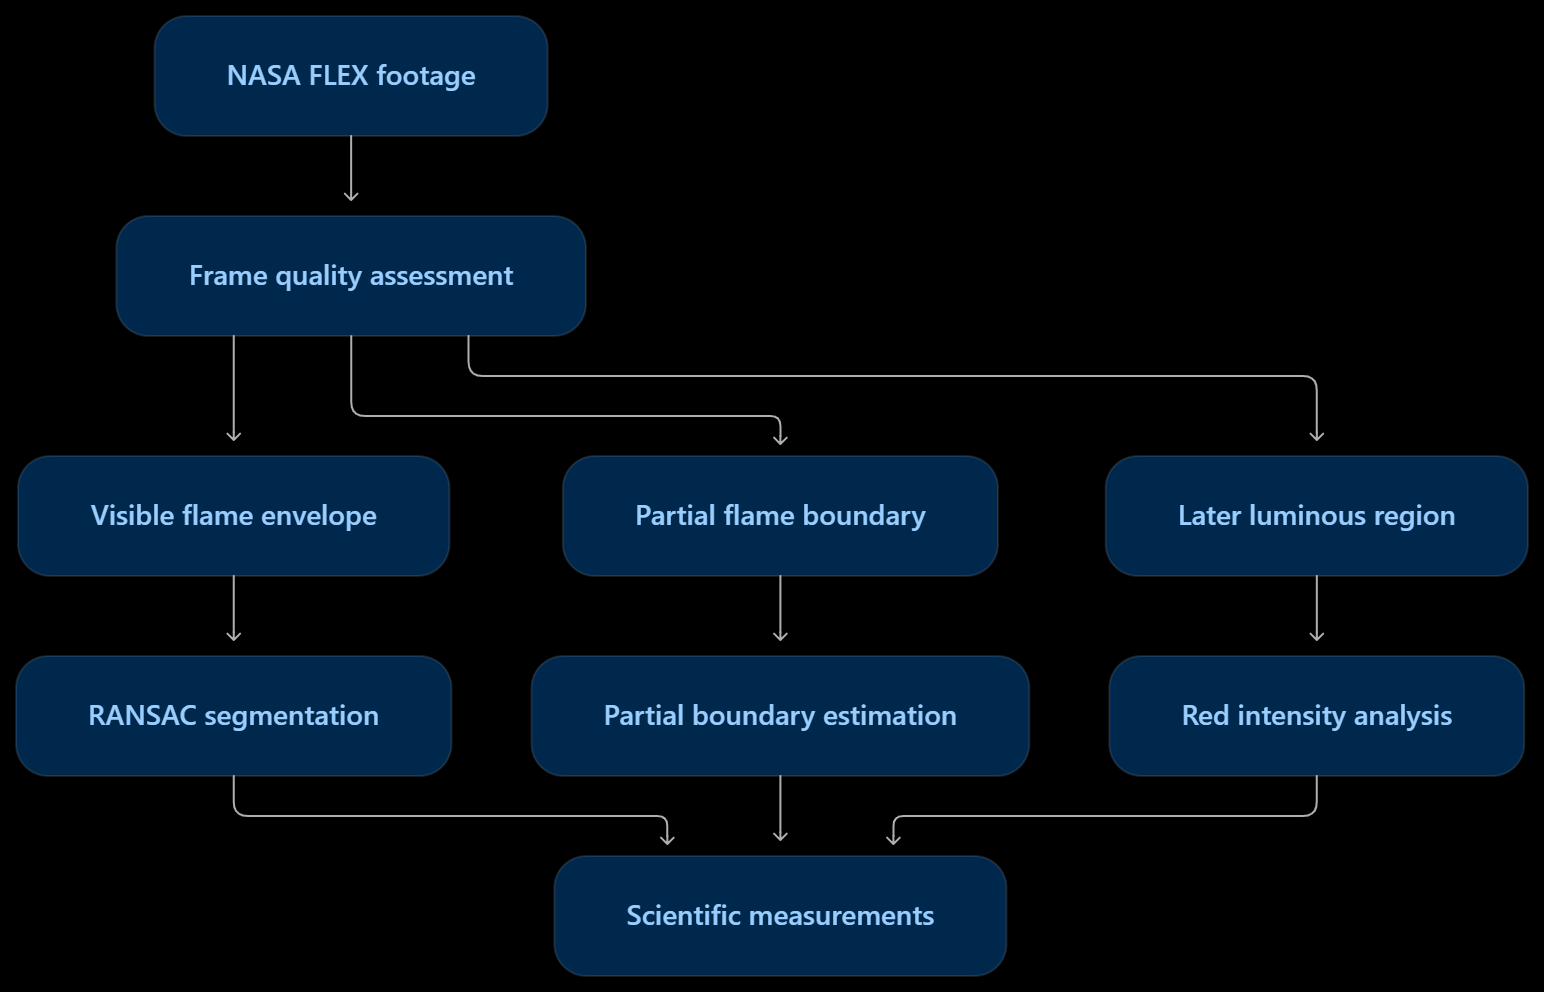](http://)

# **Extended validation**

In [ ]:
reference_groups = {
    "present": [
        82, 89, 96, 104, 105, 117, 130, 143, 156,
        168, 181, 194, 206, 220, 232, 245, 247
    ],
    "absent": [
        16, 33, 278, 284, 285, 353, 421, 488, 556, 623
    ],
    "ambiguous": [
        46, 59, 74, 75, 256, 264, 272
    ],
    "not_evaluable": [
        1, 691
    ]
}

reference_lookup = {
    frame: label
    for label, frames in reference_groups.items()
    for frame in frames
}

assert len(reference_lookup) == 36
assert set(extended_manifest["frame_index"]) == set(reference_lookup)

extended_evaluation = extended_manifest.copy()

extended_evaluation["reference_label"] = (
    extended_evaluation["frame_index"].map(reference_lookup)
)

extended_evaluation = extended_evaluation.merge(
    qc_df[
        [
            "frame_index",
            "detected",
            "quality_status",
            "angular_coverage_pct",
            "measurement_eligible"
        ]
    ],
    on="frame_index",
    how="left",
    validate="one_to_one"
)

extended_evaluation["raw_prediction"] = (
    extended_evaluation["detected"].eq(True)
)

extended_evaluation["screened_prediction"] = (
    extended_evaluation["quality_status"].isin(
        ["quality_screened", "uncertain_boundary"]
    )
)

evaluable = extended_evaluation[
    extended_evaluation["reference_label"].isin(
        ["present", "absent"]
    )
].copy()

actual = evaluable["reference_label"].eq("present")

def evaluate_detection(predicted, actual, method):
    tp = int((predicted & actual).sum())
    tn = int((~predicted & ~actual).sum())
    fp = int((predicted & ~actual).sum())
    fn = int((~predicted & actual).sum())

    precision = tp / (tp + fp) if tp + fp else np.nan
    recall = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * tp / (2 * tp + fp + fn)

    return {
        "Method": method,
        "TP": tp,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "Precision (%)": precision * 100,
        "Recall (%)": recall * 100,
        "F1 (%)": f1 * 100,
        "Accuracy (%)": (tp + tn) / len(actual) * 100
    }

validation_metrics = pd.DataFrame([
    evaluate_detection(
        evaluable["raw_prediction"],
        actual,
        "Raw RANSAC"
    ),
    evaluate_detection(
        evaluable["screened_prediction"],
        actual,
        "Phase-gated RANSAC"
    )
])

display(validation_metrics.round(2))

display(
    extended_evaluation[
        [
            "frame_index",
            "reference_label",
            "raw_prediction",
            "screened_prediction",
            "quality_status"
        ]
    ]
)

extended_evaluation.to_csv(
    WORK_DIR / "results" / "flex_extended_validation.csv",
    index=False
)

# **Red-emission temporal analysis**

In [ ]:
video_path = next(
    WORK_DIR.rglob("flex_combustion_test.mp4")
)

cap = cv2.VideoCapture(str(video_path))

fps = cap.get(cv2.CAP_PROP_FPS)

glow_records = []
glow_example = None
frame_index = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
    height, width = rgb.shape[:2]

    x1, y1 = int(width * 0.32), int(height * 0.44)
    x2, y2 = int(width * 0.68), int(height * 0.84)

    roi = rgb[y1:y2, x1:x2].astype(np.float32)

    r, g, b = roi[:, :, 0], roi[:, :, 1], roi[:, :, 2]

    red_excess = np.maximum(r - (g + b) / 2, 0)

    time_s = frame_index / fps

    if time_s >= 9.5 and rgb.max() > 8:
        glow_records.append({
            "frame_index": frame_index,
            "playback_time_s": time_s,
            "red_excess_mean": float(red_excess.mean()),
            "red_excess_p95": float(
                np.percentile(red_excess, 95)
            )
        })

    if frame_index == 623:
        glow_example = (
            rgb.copy(),
            (x1, y1, x2, y2)
        )

    frame_index += 1

cap.release()

glow_df = pd.DataFrame(glow_records)

glow_df.to_csv(
    WORK_DIR / "results" / "flex_red_emission.csv",
    index=False
)

display(
    glow_df[
        ["red_excess_mean", "red_excess_p95"]
    ].describe().round(3)
)

# **Scientific visualization**

In [ ]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(
    1, 2,
    figsize=(18, 6),
    gridspec_kw={"width_ratios": [1, 1.5]}
)

fig.patch.set_facecolor("white")

image, bounds = glow_example
x1, y1, x2, y2 = bounds

axes[0].imshow(image)

axes[0].add_patch(
    Rectangle(
        (x1, y1),
        x2 - x1,
        y2 - y1,
        fill=False,
        edgecolor="#22D3EE",
        linewidth=2,
        linestyle="--"
    )
)

axes[0].set_title(
    "Later Luminous Region | Frame 623",
    fontsize=14,
    fontweight="bold"
)

axes[0].axis("off")

axes[1].set_facecolor("#F5F7FA")

axes[1].plot(
    glow_df["playback_time_s"],
    glow_df["red_excess_mean"],
    color="#DC2626",
    linewidth=2.5,
    label="Mean red excess"
)

axes[1].plot(
    glow_df["playback_time_s"],
    glow_df["red_excess_p95"],
    color="#F59E0B",
    linewidth=2,
    label="95th percentile"
)

axes[1].set_title(
    "Temporal Evolution of Red Emission Signal",
    fontsize=14,
    fontweight="bold"
)

axes[1].set_xlabel("Video playback time (s)")
axes[1].set_ylabel("Relative digital intensity")
axes[1].grid(alpha=0.15)
axes[1].legend(frameon=False)

axes[1].spines[["top", "right"]].set_visible(False)

fig.suptitle(
    "FLEX | Post-Envelope Luminous Region Analysis",
    fontsize=23,
    fontweight="bold",
    color="#0F172A"
)

plt.tight_layout()

plt.savefig(
    WORK_DIR / "visualizations" / "flex_red_emission.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Adaptive luminous-region segmentation**

In [ ]:
def red_signal(rgb):
    image = rgb.astype(np.float32)

    return image[:, :, 0] - (
        image[:, :, 1] + image[:, :, 2]
    ) / 2


cap = cv2.VideoCapture(str(video_path))

baseline_frames = []

for index in range(278, 286):
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)
    success, frame = cap.read()

    if success:
        rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
        baseline_frames.append(red_signal(rgb))

cap.release()

baseline_signal = np.median(
    baseline_frames, axis=0
).astype(np.float32)


def segment_luminous_region(rgb, threshold=8.0):
    height, width = rgb.shape[:2]

    change = red_signal(rgb) - baseline_signal

    change = cv2.GaussianBlur(change, (7, 7), 0)

    search_region = np.zeros(
        (height, width), dtype=np.uint8
    )

    search_region[
        int(height * 0.17):int(height * 0.87),
        int(width * 0.22):int(width * 0.78)
    ] = 1

    mask = (
        (change >= threshold) &
        (search_region == 1)
    ).astype(np.uint8)

    count, labels, stats, _ = (
        cv2.connectedComponentsWithStats(mask)
    )

    final_mask = np.zeros_like(mask)

    if count > 1:
        largest = 1 + np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
        )

        final_mask[labels == largest] = 1

    contours, _ = cv2.findContours(
        final_mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    return change, final_mask, contours


image = glow_example[0]

change, luminous_mask, luminous_contours = (
    segment_luminous_region(image)
)

print("Candidate luminous area:", luminous_mask.sum(), "pixels")

# **Spatial segmentation visualization**

In [ ]:
overlay = image.copy()

cv2.drawContours(
    overlay,
    luminous_contours,
    -1,
    (34, 211, 238),
    2
)

fig, axes = plt.subplots(
    1, 4,
    figsize=(23, 6)
)

axes[0].imshow(image)
axes[0].set_title("Original imagery")

heatmap = axes[1].imshow(
    change,
    cmap="inferno",
    vmin=0,
    vmax=80
)

axes[1].set_title("Background-relative red signal")

fig.colorbar(
    heatmap,
    ax=axes[1],
    fraction=0.046,
    pad=0.04
)

axes[2].imshow(
    luminous_mask,
    cmap="gray"
)

axes[2].set_title("Candidate luminous mask")

axes[3].imshow(overlay)
axes[3].set_title("Irregular boundary overlay")

for ax in axes:
    ax.axis("off")
    ax.title.set_fontsize(13)
    ax.title.set_fontweight("bold")

fig.suptitle(
    "FLEX | Spatial Analysis of the Luminous Region",
    fontsize=24,
    fontweight="bold",
    color="#0F172A"
)

plt.tight_layout()

plt.savefig(
    WORK_DIR / "visualizations" /
    "flex_luminous_segmentation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Multi-threshold luminous-region analysis**

In [ ]:
image = glow_example[0]

change = red_signal(image) - baseline_signal
change = cv2.GaussianBlur(change, (7, 7), 0)

thresholds = [15, 25, 40, 55]

colors = [
    (34, 211, 238),
    (16, 185, 129),
    (250, 204, 21),
    (239, 68, 68)
]

overlay = image.copy()
records = []

for threshold, color in zip(thresholds, colors):
    mask = (change >= threshold).astype(np.uint8)

    count, labels, stats, _ = (
        cv2.connectedComponentsWithStats(mask)
    )

    selected = np.zeros_like(mask)

    if count > 1:
        largest = 1 + np.argmax(
            stats[1:, cv2.CC_STAT_AREA]
        )

        selected[labels == largest] = 1

    contours, _ = cv2.findContours(
        selected,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    cv2.drawContours(
        overlay, contours, -1, color, 2
    )

    records.append({
        "threshold": threshold,
        "area_pixels": int(selected.sum()),
        "frame_percentage": (
            100 * selected.mean()
        )
    })

gray = cv2.cvtColor(
    image, cv2.COLOR_RGB2GRAY
).astype(np.float32)

detail = (
    cv2.GaussianBlur(gray, (0, 0), 1.5)
    - cv2.GaussianBlur(gray, (0, 0), 8)
)

display(pd.DataFrame(records).round(3))

# **Final spatial visualization**

In [ ]:
from matplotlib.lines import Line2D

fig, axes = plt.subplots(
    2, 2, figsize=(18, 12)
)

axes[0, 0].imshow(image)
axes[0, 0].set_title("Original NASA Imagery")

heatmap = axes[0, 1].imshow(
    change,
    cmap="inferno",
    vmin=0,
    vmax=80
)

axes[0, 1].set_title("Red Signal Distribution")

fig.colorbar(
    heatmap,
    ax=axes[0, 1],
    fraction=0.046,
    pad=0.04
)

axes[1, 0].imshow(overlay)
axes[1, 0].set_title("Multi-Level Intensity Boundaries")

handles = [
    Line2D(
        [0], [0],
        color=np.array(color) / 255,
        linewidth=3,
        label=f"Threshold {threshold}"
    )
    for threshold, color in zip(thresholds, colors)
]

axes[1, 0].legend(
    handles=handles,
    loc="lower center",
    ncol=2,
    frameon=True
)

axes[1, 1].imshow(
    detail,
    cmap="gray",
    vmin=-12,
    vmax=12
)

axes[1, 1].set_title("Internal Luminous Structure Enhancement")

for ax in axes.flat:
    ax.axis("off")
    ax.title.set_fontsize(14)
    ax.title.set_fontweight("bold")

fig.suptitle(
    "FLEX | Multilevel Luminous Structure Analysis",
    fontsize=26,
    fontweight="bold",
    color="#0F172A"
)

plt.tight_layout()

plt.savefig(
    WORK_DIR / "visualizations" /
    "flex_multilevel_luminous_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Partial Flame Boundary Detection**

In [ ]:
reliable_frames = qc_df[
    qc_df["measurement_eligible"].eq(True)
].dropna(
    subset=[
        "centroid_x",
        "centroid_y",
        "radius_pixels"
    ]
).copy()

assert not reliable_frames.empty

PARTIAL_CONFIG = {
    "angular_bins": 72,
    "minimum_arc_deg": 60,
    "minimum_signal": 3.0,
    "noise_multiplier": 3.0,
    "maximum_reference_distance": 45
}


def detect_partial_boundary(rgb, frame_index):
    config = PARTIAL_CONFIG

    reference = reliable_frames.iloc[
        (
            reliable_frames["frame_index"]
            - frame_index
        ).abs().argmin()
    ]

    distance = abs(
        reference["frame_index"] - frame_index
    )

    result = {
        "frame_index": frame_index,
        "reference_frame": int(reference["frame_index"]),
        "detected": False,
        "coverage_pct": 0.0,
        "longest_arc_deg": 0.0,
        "status": "insufficient_evidence",
        "points": np.empty((0, 2))
    }

    if distance > config["maximum_reference_distance"]:
        result["status"] = "outside_tracking_window"
        return result

    cx = float(reference["centroid_x"])
    cy = float(reference["centroid_y"])
    radius = float(reference["radius_pixels"])

    image = rgb.astype(np.float32)

    signal = image[:, :, 2] - image[:, :, 0]

    signal = cv2.GaussianBlur(
        signal, (5, 5), 0
    )

    bins = config["angular_bins"]

    angles = np.linspace(
        0, 2 * np.pi,
        bins,
        endpoint=False
    )

    radii = np.linspace(
        radius * 0.70,
        radius * 1.50,
        100
    )

    map_x = (
        cx + np.cos(angles[:, None]) * radii[None, :]
    ).astype(np.float32)

    map_y = (
        cy + np.sin(angles[:, None]) * radii[None, :]
    ).astype(np.float32)

    profiles = cv2.remap(
        signal,
        map_x,
        map_y,
        cv2.INTER_LINEAR,
        borderMode=cv2.BORDER_CONSTANT
    )

    search_indices = np.where(
        (radii >= radius * 0.80) &
        (radii <= radius * 1.20)
    )[0]

    background = profiles[
        :, radii >= radius * 1.30
    ]

    baseline = np.median(
        background, axis=1
    )

    noise = 1.4826 * np.median(
        np.abs(background - baseline[:, None]),
        axis=1
    )

    peak_indices = search_indices[
        np.argmax(
            profiles[:, search_indices],
            axis=1
        )
    ]

    row_indices = np.arange(bins)

    peak_values = profiles[
        row_indices,
        peak_indices
    ]

    prominence = peak_values - baseline

    supported = (
        (
            prominence >= np.maximum(
                config["minimum_signal"],
                config["noise_multiplier"] * noise
            )
        )
        & (peak_values >= config["minimum_signal"])
        & (peak_indices > search_indices[0])
        & (peak_indices < search_indices[-1])
    )

    longest_run = 0
    longest_end = 0
    current_run = 0

    for i, value in enumerate(np.tile(supported, 2)):
        current_run = current_run + 1 if value else 0

        if current_run > longest_run:
            longest_run = current_run
            longest_end = i

    longest_run = min(longest_run, bins)

    arc_indices = np.arange(
        longest_end - longest_run + 1,
        longest_end + 1
    ) % bins

    longest_arc = longest_run * (360 / bins)

    detected = (
        longest_arc >= config["minimum_arc_deg"]
    )

    points = np.column_stack([
        map_x[row_indices, peak_indices],
        map_y[row_indices, peak_indices]
    ])[arc_indices]

    result.update({
        "detected": bool(detected),
        "coverage_pct": float(supported.mean() * 100),
        "longest_arc_deg": float(longest_arc),
        "status": (
            "candidate_visible_arc"
            if detected
            else "insufficient_evidence"
        ),
        "points": points
    })

    return result


partial_test_frames = [
    16, 33, 82,
    89, 96, 145,
    251, 256, 264,
    272, 278, 285
]

partial_results = []
partial_images = {}

cap = cv2.VideoCapture(str(video_path))

fps = cap.get(cv2.CAP_PROP_FPS)

assert cap.isOpened()
assert fps > 0

for index in partial_test_frames:
    cap.set(cv2.CAP_PROP_POS_FRAMES, index)

    success, frame = cap.read()

    if not success:
        continue

    rgb = cv2.cvtColor(
        frame, cv2.COLOR_BGR2RGB
    )

    partial_images[index] = rgb

    partial_results.append(
        detect_partial_boundary(rgb, index)
    )

cap.release()

partial_evaluation = pd.DataFrame([
    {
        key: value
        for key, value in result.items()
        if key != "points"
    }
    for result in partial_results
])

partial_evaluation.to_csv(
    WORK_DIR / "results" /
    "flex_partial_boundary_evaluation.csv",
    index=False
)

display(partial_evaluation.round(2))

# **Partial Boundary Scientific Visualization**

In [ ]:
fig, axes = plt.subplots(
    4, 3,
    figsize=(19, 17)
)

fig.patch.set_facecolor("white")

for ax in axes.flat:
    ax.axis("off")

for ax, result in zip(axes.flat, partial_results):
    index = result["frame_index"]

    image = partial_images[index]
    points = result["points"]

    ax.imshow(image)

    if result["detected"] and len(points):
        ax.scatter(
            points[:, 0],
            points[:, 1],
            s=15,
            color="#22D3EE",
            edgecolors="none"
        )

    if result["status"] == "outside_tracking_window":
        status = "Outside tracking window"
        color = "#64748B"

    elif result["detected"]:
        status = "Candidate visible arc"
        color = "#059669"

    else:
        status = "Insufficient evidence"
        color = "#DC2626"

    ax.set_title(
        f"Frame {index:03d} | {index / fps:.2f} s",
        fontsize=14,
        fontweight="bold",
        color="#0F172A",
        pad=10
    )

    ax.text(
        0.5, 0.08,
        status,
        transform=ax.transAxes,
        ha="center",
        color="white",
        fontsize=11,
        fontweight="bold",
        bbox=dict(
            facecolor=color,
            edgecolor="none",
            alpha=0.95,
            pad=5
        )
    )

    ax.text(
        0.5, 0.01,
        (
            f"Coverage: {result['coverage_pct']:.1f}%"
            f" | Arc: {result['longest_arc_deg']:.0f}°"
        ),
        transform=ax.transAxes,
        ha="center",
        color="white",
        fontsize=10,
        bbox=dict(
            facecolor="#0F172A",
            edgecolor="none",
            alpha=0.90,
            pad=4
        )
    )

fig.suptitle(
    "FLEX | Partial Flame Boundary Detection",
    fontsize=27,
    fontweight="bold",
    color="#0F172A",
    y=0.99
)

fig.text(
    0.5, 0.963,
    "Evidence-Based Radial Boundary Extraction",
    ha="center",
    fontsize=14,
    color="#64748B"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.savefig(
    WORK_DIR / "visualizations" /
    "flex_partial_boundary.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Multi-source luminous object detection**

In [ ]:
def detect_luminous_sources(rgb):
    image = rgb.astype(np.float32)

    red = image[:, :, 0]
    green = image[:, :, 1]
    blue = image[:, :, 2]

    gray = cv2.cvtColor(
        rgb, cv2.COLOR_RGB2GRAY
    ).astype(np.float32)

    intensity = image.max(axis=2)

    red_excess = red - (green + blue) / 2

    background = cv2.GaussianBlur(
        intensity, (0, 0), 12
    )

    local_contrast = intensity - background

    bright_mask = (
        (intensity >= 115) &
        (gray >= 65) &
        (local_contrast >= 15)
    )

    red_mask = (
        (red >= 45) &
        (red_excess >= 15) &
        (local_contrast >= 10)
    )

    mask = (
        bright_mask | red_mask
    ).astype(np.uint8)

    count, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            mask, connectivity=8
        )
    )

    sources = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        if area < 6 or area > 5000:
            continue

        if w > 130 or h > 130:
            continue

        component = labels == i

        sources.append({
            "bbox": (
                int(x), int(y),
                int(w), int(h)
            ),
            "area_pixels": int(area),
            "centroid_x": float(centroids[i][0]),
            "centroid_y": float(centroids[i][1]),
            "mean_brightness": float(
                gray[component].mean()
            ),
            "mean_red_excess": float(
                red_excess[component].mean()
            )
        })

    sources.sort(
        key=lambda item: item["area_pixels"],
        reverse=True
    )

    return sources


luminous_detections = {}
luminous_records = []

for index, image in partial_images.items():
    sources = detect_luminous_sources(image)

    luminous_detections[index] = sources

    for source_id, source in enumerate(sources, 1):
        luminous_records.append({
            "frame_index": index,
            "source_id": source_id,
            **source
        })

luminous_df = pd.DataFrame(luminous_records)

luminous_summary = pd.DataFrame([
    {
        "frame_index": index,
        "luminous_candidates": len(sources)
    }
    for index, sources in luminous_detections.items()
])

display(luminous_summary)

luminous_df.to_csv(
    WORK_DIR / "results" /
    "flex_luminous_sources.csv",
    index=False
)

# **Multi-source detection visualization**

In [ ]:
fig, axes = plt.subplots(
    4, 3,
    figsize=(19, 16)
)

for ax in axes.flat:
    ax.axis("off")

for ax, (index, image) in zip(
    axes.flat,
    partial_images.items()
):
    overlay = image.copy()

    sources = luminous_detections[index]

    for source_id, source in enumerate(sources, 1):
        x, y, w, h = source["bbox"]

        color = (34, 211, 238)

        cv2.rectangle(
            overlay,
            (x - 3, y - 3),
            (x + w + 3, y + h + 3),
            color,
            2
        )

        cv2.putText(
            overlay,
            f"L{source_id}",
            (x, max(15, y - 7)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.45,
            color,
            1,
            cv2.LINE_AA
        )

    ax.imshow(overlay)

    ax.set_title(
        f"Frame {index:03d} | {index / fps:.2f} s",
        fontsize=14,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.04,
        f"Luminous candidates: {len(sources)}",
        transform=ax.transAxes,
        ha="center",
        color="white",
        fontsize=11,
        bbox=dict(
            facecolor="#0F172A",
            edgecolor="none",
            alpha=0.9,
            pad=5
        )
    )

fig.suptitle(
    "FLEX | Multi-Source Luminous Object Detection",
    fontsize=26,
    fontweight="bold",
    color="#0F172A"
)

plt.tight_layout(
    rect=[0, 0, 1, 0.96]
)

plt.savefig(
    WORK_DIR / "visualizations" /
    "flex_luminous_source_detection.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Refined luminous-source detector**

In [ ]:
SOURCE_REGIONS = {
    "central": (0.36, 0.20, 0.64, 0.75),
    "upper_external": (0.20, 0.10, 0.36, 0.40),
    "lower_external": (0.66, 0.72, 0.85, 1.00),
    "early_ignition": (0.25, 0.37, 0.62, 0.73)
}


def detect_refined_sources(rgb, frame_index):
    height, width = rgb.shape[:2]

    time_s = frame_index / fps

    if time_s < 0.9:
        return [], "apparatus_phase_not_evaluated"

    image = rgb.astype(np.float32)

    gray = cv2.cvtColor(
        rgb, cv2.COLOR_RGB2GRAY
    )

    red_excess = image[:, :, 0] - (
        image[:, :, 1] + image[:, :, 2]
    ) / 2

    if time_s < 2.5:
        active_regions = ["early_ignition"]
    elif time_s < 4.0:
        active_regions = [
            "central",
            "upper_external",
            "lower_external"
        ]
    else:
        active_regions = ["central"]

    sources = []

    for name in active_regions:
        bounds = SOURCE_REGIONS[name]

        x1 = int(bounds[0] * width)
        y1 = int(bounds[1] * height)
        x2 = int(bounds[2] * width)
        y2 = int(bounds[3] * height)

        roi_gray = gray[y1:y2, x1:x2]

        roi_red = image[
            y1:y2, x1:x2, 0
        ]

        roi_excess = red_excess[
            y1:y2, x1:x2
        ]

        if name == "early_ignition":
            mask = (
                (roi_red >= 45) &
                (roi_excess >= 15)
            ).astype(np.uint8)

        else:
            mask = (
                roi_gray >= 110
            ).astype(np.uint8)

        count, labels, stats, centroids = (
            cv2.connectedComponentsWithStats(
                mask, connectivity=8
            )
        )

        for i in range(1, count):
            x, y, w, h, area = stats[i]

            if area < 6:
                continue

            component = labels == i

            sources.append({
                "region": name,
                "bbox": (
                    int(x + x1),
                    int(y + y1),
                    int(w),
                    int(h)
                ),
                "area_pixels": int(area),
                "centroid_x": float(
                    centroids[i][0] + x1
                ),
                "centroid_y": float(
                    centroids[i][1] + y1
                ),
                "mean_brightness": float(
                    roi_gray[component].mean()
                ),
                "peak_brightness": int(
                    roi_gray[component].max()
                )
            })

    return sources, "analyzed"


refined_detections = {}
refined_status = {}
refined_records = []

for index, image in partial_images.items():
    sources, status = detect_refined_sources(
        image, index
    )

    refined_detections[index] = sources
    refined_status[index] = status

    for source_id, source in enumerate(sources, 1):
        refined_records.append({
            "frame_index": index,
            "source_id": source_id,
            **source
        })

refined_df = pd.DataFrame(refined_records)

refined_summary = pd.DataFrame([
    {
        "frame_index": index,
        "previous_candidates": len(
            luminous_detections[index]
        ),
        "refined_candidates": len(sources),
        "status": refined_status[index]
    }
    for index, sources in refined_detections.items()
])

display(refined_summary)

refined_df.to_csv(
    WORK_DIR / "results" /
    "flex_refined_luminous_sources.csv",
    index=False
)

# **Refined detection visualization**

In [ ]:
REGION_COLORS = {
    "central": (34, 211, 238),
    "upper_external": (250, 204, 21),
    "lower_external": (250, 204, 21),
    "early_ignition": (249, 115, 22)
}

fig, axes = plt.subplots(
    4, 3, figsize=(19, 17)
)

for ax in axes.flat:
    ax.axis("off")

for ax, (index, image) in zip(
    axes.flat,
    partial_images.items()
):
    overlay = image.copy()

    sources = refined_detections[index]

    for source_id, source in enumerate(sources, 1):
        x, y, w, h = source["bbox"]

        color = REGION_COLORS[source["region"]]

        cv2.rectangle(
            overlay,
            (x - 4, y - 4),
            (x + w + 4, y + h + 4),
            color,
            2
        )

        cv2.putText(
            overlay,
            f"L{source_id}",
            (x, max(15, y - 8)),
            cv2.FONT_HERSHEY_SIMPLEX,
            0.55,
            color,
            1,
            cv2.LINE_AA
        )

    ax.imshow(overlay)

    if refined_status[index] == "apparatus_phase_not_evaluated":
        status = "Apparatus phase | Not evaluated"
    else:
        status = f"Compact luminous candidates: {len(sources)}"

    ax.set_title(
        f"Frame {index:03d} | {index / fps:.2f} s",
        fontsize=14,
        fontweight="bold"
    )

    ax.text(
        0.5, 0.04,
        status,
        transform=ax.transAxes,
        ha="center",
        color="white",
        fontsize=11,
        bbox=dict(
            facecolor="#0F172A",
            edgecolor="none",
            alpha=0.95,
            pad=5
        )
    )

handles = [
    Line2D(
        [0], [0],
        color="#22D3EE",
        linewidth=3,
        label="Central luminous source"
    ),
    Line2D(
        [0], [0],
        color="#FACC15",
        linewidth=3,
        label="External luminous source"
    ),
    Line2D(
        [0], [0],
        color="#F97316",
        linewidth=3,
        label="Early red luminous source"
    )
]

fig.legend(
    handles=handles,
    loc="lower center",
    ncol=3,
    frameon=False,
    fontsize=12
)

fig.suptitle(
    "FLEX | Refined Luminous Source Detection",
    fontsize=26,
    fontweight="bold",
    color="#0F172A"
)

plt.tight_layout(
    rect=[0, 0.04, 1, 0.96]
)

plt.savefig(
    WORK_DIR / "visualizations" /
    "flex_refined_luminous_sources.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Separation of high-intensity luminous cores**

In [ ]:
def detect_luminous_cores(rgb, threshold=200):
    height, width = rgb.shape[:2]

    x1, y1 = int(width * 0.36), int(height * 0.20)
    x2, y2 = int(width * 0.64), int(height * 0.75)

    gray = cv2.cvtColor(
        rgb, cv2.COLOR_RGB2GRAY
    )

    roi = gray[y1:y2, x1:x2]

    mask = (roi >= threshold).astype(np.uint8)

    count, labels, stats, centroids = (
        cv2.connectedComponentsWithStats(
            mask, connectivity=8
        )
    )

    cores = []

    for i in range(1, count):
        x, y, w, h, area = stats[i]

        if area < 6:
            continue

        cores.append({
            "bbox": (
                int(x + x1),
                int(y + y1),
                int(w),
                int(h)
            ),
            "area_pixels": int(area),
            "centroid_x": float(centroids[i][0] + x1),
            "centroid_y": float(centroids[i][1] + y1),
            "mean_brightness": float(
                roi[labels == i].mean()
            )
        })

    return cores


core_test_frames = [82, 89, 96, 145, 251, 285]

core_records = []

for index in core_test_frames:
    for threshold in [180, 200, 220]:
        cores = detect_luminous_cores(
            partial_images[index],
            threshold
        )

        core_records.append({
            "frame_index": index,
            "threshold": threshold,
            "luminous_cores": len(cores)
        })

core_evaluation = pd.DataFrame(core_records)

display(
    core_evaluation.pivot(
        index="frame_index",
        columns="threshold",
        values="luminous_cores"
    )
)

# **Combined luminous-source and core visualization**

In [ ]:
from matplotlib.patches import Rectangle

fig, axes = plt.subplots(
    2, 3, figsize=(19, 11)
)

for ax, index in zip(axes.flat, core_test_frames):
    image = partial_images[index]

    ax.imshow(image)

    for source in refined_detections[index]:
        x, y, w, h = source["bbox"]

        ax.add_patch(
            Rectangle(
                (x, y), w, h,
                fill=False,
                edgecolor="#22D3EE",
                linewidth=1.5,
                linestyle="--"
            )
        )

    cores = detect_luminous_cores(
        image, threshold=200
    )

    for i, core in enumerate(cores, 1):
        x, y, w, h = core["bbox"]

        ax.add_patch(
            Rectangle(
                (x, y), w, h,
                fill=False,
                edgecolor="#FACC15",
                linewidth=2
            )
        )

        ax.text(
            x, max(10, y - 5),
            f"C{i}",
            color="#FACC15",
            fontsize=10,
            fontweight="bold"
        )

    ax.set_title(
        f"Frame {index:03d} | {index / fps:.2f} s",
        fontsize=14,
        fontweight="bold"
    )

    ax.axis("off")

fig.legend(
    handles=[
        Line2D(
            [0], [0],
            color="#22D3EE",
            linestyle="--",
            label="Connected luminous region"
        ),
        Line2D(
            [0], [0],
            color="#FACC15",
            linewidth=2,
            label="High-intensity core at threshold 200"
        )
    ],
    loc="lower center",
    ncol=2,
    frameon=False,
    fontsize=12
)

fig.suptitle(
    "FLEX | Luminous Core Separation",
    fontsize=26,
    fontweight="bold",
    color="#0F172A"
)

plt.tight_layout(rect=[0, 0.05, 1, 0.95])

plt.savefig(
    WORK_DIR / "visualizations" /
    "flex_luminous_core_separation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# **Unified FLEX computer vision pipeline**

In [ ]:
from tqdm.auto import tqdm

qc_lookup = qc_df.set_index("frame_index")

integrated_records = []
integrated_sources = []
integrated_cores = []
frame_visual_data = {}

RED_THRESHOLDS = [15, 25, 40, 55]


def analyze_red_regions(rgb):
    signal = red_signal(rgb) - baseline_signal

    signal = cv2.GaussianBlur(
        signal, (7, 7), 0
    )

    measurements = {}
    selected_contours = []

    for threshold in RED_THRESHOLDS:
        mask = (signal >= threshold).astype(np.uint8)

        count, labels, stats, _ = (
            cv2.connectedComponentsWithStats(mask)
        )

        area = 0

        if count > 1:
            largest = 1 + np.argmax(
                stats[1:, cv2.CC_STAT_AREA]
            )

            component = (
                labels == largest
            ).astype(np.uint8)

            area = int(component.sum())

            if threshold == 40:
                selected_contours, _ = cv2.findContours(
                    component,
                    cv2.RETR_EXTERNAL,
                    cv2.CHAIN_APPROX_SIMPLE
                )

        measurements[f"red_area_t{threshold}"] = area

    return measurements, selected_contours


cap = cv2.VideoCapture(str(video_path))

assert cap.isOpened()

fps = cap.get(cv2.CAP_PROP_FPS)
total_frames = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))

assert fps > 0

progress = tqdm(
    total=total_frames,
    desc="Unified FLEX analysis",
    unit="frame"
)

index = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    rgb = cv2.cvtColor(
        frame, cv2.COLOR_BGR2RGB
    )

    time_s = index / fps
    qc = qc_lookup.loc[index]

    blank = qc["quality_status"] == "blank_frame"

    eligible = bool(qc["measurement_eligible"])

    record = {
        "frame_index": index,
        "playback_time_s": time_s,
        "quality_status": qc["quality_status"],
        "envelope_measurement_eligible": eligible,
        "envelope_area_pixels": (
            qc["area_pixels"] if eligible else None
        ),
        "envelope_diameter_pixels": (
            qc["diameter_pixels"] if eligible else None
        ),
        "envelope_radius_pixels": (
            qc["radius_pixels"] if eligible else None
        ),
        "envelope_centroid_x": (
            qc["centroid_x"] if eligible else None
        ),
        "envelope_centroid_y": (
            qc["centroid_y"] if eligible else None
        ),
        "boundary_brightness_mean": (
            qc["boundary_brightness_mean"]
            if eligible else None
        ),
        "partial_boundary_detected": None,
        "partial_coverage_pct": None,
        "partial_arc_deg": None,
        "compact_source_count": None,
        "luminous_core_count": None,
        "source_analysis_status": "not_evaluated",
        "red_area_t15": None,
        "red_area_t25": None,
        "red_area_t40": None,
        "red_area_t55": None,
        "calibration_status": "not_calibrated"
    }

    sources = []
    cores = []
    partial_points = np.empty((0, 2))
    red_contours = []

    if not blank:

        if not eligible and 2.5 <= time_s < 9.5:
            partial = detect_partial_boundary(
                rgb, index
            )

            if partial["status"] != "outside_tracking_window":
                record["partial_boundary_detected"] = (
                    partial["detected"]
                )

                record["partial_coverage_pct"] = (
                    partial["coverage_pct"]
                )

                record["partial_arc_deg"] = (
                    partial["longest_arc_deg"]
                )

                if partial["detected"]:
                    partial_points = partial["points"]

        if time_s < 9.5:
            sources, source_status = (
                detect_refined_sources(rgb, index)
            )

            record["source_analysis_status"] = source_status

            if source_status == "analyzed":
                record["compact_source_count"] = len(sources)

            if 2.5 <= time_s:
                cores = detect_luminous_cores(
                    rgb, threshold=200
                )

                record["luminous_core_count"] = len(cores)

        else:
            record["source_analysis_status"] = (
                "diffuse_glow_analysis"
            )

            red_measurements, red_contours = (
                analyze_red_regions(rgb)
            )

            record.update(red_measurements)

    for source_id, source in enumerate(sources, 1):
        integrated_sources.append({
            "frame_index": index,
            "playback_time_s": time_s,
            "source_id": source_id,
            **source
        })

    for core_id, core in enumerate(cores, 1):
        integrated_cores.append({
            "frame_index": index,
            "playback_time_s": time_s,
            "core_id": core_id,
            **core
        })

    frame_visual_data[index] = {
        "sources": sources,
        "cores": cores,
        "partial_points": partial_points,
        "red_contours": red_contours
    }

    integrated_records.append(record)

    index += 1
    progress.update(1)

cap.release()
progress.close()

integrated_df = pd.DataFrame(integrated_records)
integrated_sources_df = pd.DataFrame(integrated_sources)
integrated_cores_df = pd.DataFrame(integrated_cores)

assert len(integrated_df) == total_frames
assert integrated_df["frame_index"].is_unique

integrated_df.to_csv(
    WORK_DIR / "results" /
    "flex_integrated_analysis.csv",
    index=False
)

integrated_sources_df.to_csv(
    WORK_DIR / "results" /
    "flex_integrated_luminous_sources.csv",
    index=False
)

integrated_cores_df.to_csv(
    WORK_DIR / "results" /
    "flex_integrated_luminous_cores.csv",
    index=False
)

integration_summary = pd.DataFrame([
    {
        "Metric": "Total processed frames",
        "Value": len(integrated_df)
    },
    {
        "Metric": "Quality-screened envelope measurements",
        "Value": int(
            integrated_df[
                "envelope_measurement_eligible"
            ].sum()
        )
    },
    {
        "Metric": "Supplementary partial boundary detections",
        "Value": int(
            integrated_df[
                "partial_boundary_detected"
            ].eq(True).sum()
        )
    },
    {
        "Metric": "Compact luminous candidate observations",
        "Value": len(integrated_sources_df)
    },
    {
        "Metric": "High-intensity core observations",
        "Value": len(integrated_cores_df)
    },
    {
        "Metric": "Red luminous-region analyzed frames",
        "Value": int(
            integrated_df["red_area_t40"].notna().sum()
        )
    }
])

display(integration_summary)
display(integrated_df.head(10))

# **Integrated Annotated Video**

In [ ]:
import shutil
import subprocess
from IPython.display import Video, display

analysis_lookup = integrated_df.set_index("frame_index")

cap = cv2.VideoCapture(str(video_path))

width = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
height = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
fps = cap.get(cv2.CAP_PROP_FPS)

PANEL_WIDTH = 340
HEADER_HEIGHT = 60
FOOTER_HEIGHT = 40

canvas_width = width + PANEL_WIDTH
canvas_height = height + HEADER_HEIGHT + FOOTER_HEIGHT

raw_output = (
    WORK_DIR / "visualizations" /
    "flex_integrated_raw.mp4"
)

final_output = (
    WORK_DIR / "visualizations" /
    "flex_integrated_annotated.mp4"
)

writer = cv2.VideoWriter(
    str(raw_output),
    cv2.VideoWriter_fourcc(*"mp4v"),
    fps,
    (canvas_width, canvas_height)
)

assert cap.isOpened()
assert writer.isOpened()

NAVY = (42, 23, 15)
WHITE = (245, 245, 245)
MUTED = (160, 148, 130)
CYAN = (238, 211, 34)
YELLOW = (21, 204, 250)
ORANGE = (22, 115, 249)
GREEN = (129, 185, 16)


def put_text(image, text, x, y, scale=0.5,
             color=WHITE, thickness=1):

    cv2.putText(
        image,
        str(text),
        (int(x), int(y)),
        cv2.FONT_HERSHEY_SIMPLEX,
        scale,
        color,
        thickness,
        cv2.LINE_AA
    )


def format_value(value, decimals=0):
    if pd.isna(value):
        return "N/A"

    return f"{value:,.{decimals}f}"


progress = tqdm(
    total=len(integrated_df),
    desc="Rendering integrated visualization",
    unit="frame"
)

index = 0

while True:
    success, frame = cap.read()

    if not success:
        break

    row = analysis_lookup.loc[index]
    visuals = frame_visual_data[index]

    overlay = frame.copy()

    if row["envelope_measurement_eligible"]:

        center = (
            int(round(row["envelope_centroid_x"])),
            int(round(row["envelope_centroid_y"]))
        )

        radius = int(
            round(row["envelope_radius_pixels"])
        )

        cv2.circle(
            overlay, center, radius,
            CYAN, 2, cv2.LINE_AA
        )

        cv2.drawMarker(
            overlay, center, CYAN,
            cv2.MARKER_CROSS,
            12, 1
        )

    for point in visuals["partial_points"]:
        cv2.circle(
            overlay,
            tuple(np.round(point).astype(int)),
            2,
            GREEN,
            -1
        )

    for source in visuals["sources"]:
        x, y, w, h = source["bbox"]

        color = (
            CYAN if source["region"] == "central"
            else ORANGE
        )

        cv2.rectangle(
            overlay,
            (x, y),
            (x + w, y + h),
            color,
            1
        )

    for core in visuals["cores"]:
        x, y, w, h = core["bbox"]

        cv2.rectangle(
            overlay,
            (x, y),
            (x + w, y + h),
            YELLOW,
            2
        )

    if visuals["red_contours"]:
        cv2.drawContours(
            overlay,
            visuals["red_contours"],
            -1,
            ORANGE,
            2
        )

    canvas = np.full(
        (canvas_height, canvas_width, 3),
        NAVY,
        dtype=np.uint8
    )

    canvas[
        HEADER_HEIGHT:HEADER_HEIGHT + height,
        :width
    ] = overlay

    put_text(
        canvas,
        "THE MOON | FLEX Visual Intelligence",
        22, 38,
        0.85, WHITE, 2
    )

    panel_x = width + 22

    put_text(
        canvas,
        "EXPERIMENT ANALYSIS",
        panel_x, 90,
        0.58, CYAN, 2
    )

    status = row["quality_status"]

    if row["envelope_measurement_eligible"]:
        status = "Quality-screened envelope"
    elif pd.notna(row["partial_boundary_detected"]) and bool(
        row["partial_boundary_detected"]
    ):
        status = "Candidate partial boundary"
    elif pd.notna(row["red_area_t40"]):
        status = "Later luminous region"
    elif row["quality_status"] == "blank_frame":
        status = "Blank frame"
    elif row["source_analysis_status"] == "apparatus_phase_not_evaluated":
        status = "Apparatus phase"
    else:
        status = "No reliable envelope"

    metrics = [
        ("Frame", f"{index + 1:03d} / {len(integrated_df)}"),
        ("Playback time", f"{index / fps:.2f} s"),
        ("Visual status", status),
        (
            "Envelope diameter",
            format_value(
                row["envelope_diameter_pixels"], 1
            ) + " px"
            if pd.notna(row["envelope_diameter_pixels"])
            else "N/A"
        ),
        (
            "Envelope area",
            format_value(
                row["envelope_area_pixels"]
            ) + " px^2"
            if pd.notna(row["envelope_area_pixels"])
            else "N/A"
        ),
        (
            "Partial arc",
            format_value(row["partial_arc_deg"], 0)
            + " deg"
            if pd.notna(row["partial_arc_deg"])
            else "N/A"
        ),
        (
            "Luminous candidates",
            format_value(row["compact_source_count"])
        ),
        (
            "High-intensity cores",
            format_value(row["luminous_core_count"])
        ),
        (
            "Red area | Threshold 40",
            format_value(row["red_area_t40"])
            + " px^2"
            if pd.notna(row["red_area_t40"])
            else "N/A"
        )
    ]

    y = 120

    for label, value in metrics:
        put_text(
            canvas, label,
            panel_x, y,
            0.38, MUTED
        )

        put_text(
            canvas, value,
            panel_x, y + 20,
            0.48, WHITE
        )

        y += 48

    footer_y = HEADER_HEIGHT + height + 25

    put_text(
        canvas,
        "Source: NASA GSFC | FLEX | PSI-69 | Pixel-space measurements | Not calibrated",
        20, footer_y,
        0.48, WHITE
    )

    writer.write(canvas)

    index += 1
    progress.update(1)

cap.release()
writer.release()
progress.close()

assert index == len(integrated_df)

if shutil.which("ffmpeg"):
    subprocess.run([
        "ffmpeg",
        "-y",
        "-i", str(raw_output),
        "-c:v", "libx264",
        "-crf", "18",
        "-pix_fmt", "yuv420p",
        "-movflags", "+faststart",
        str(final_output)
    ], check=True, capture_output=True)

else:
    shutil.copyfile(raw_output, final_output)

verification = cv2.VideoCapture(
    str(final_output)
)

rendered_frames = int(
    verification.get(cv2.CAP_PROP_FRAME_COUNT)
)

verification.release()

assert rendered_frames == len(integrated_df)

print("Rendered frames:", rendered_frames)
print("Video resolution:", canvas_width, "x", canvas_height)
print("Output:", final_output)

display(
    Video(
        str(final_output),
        embed=True,
        width=1100
    )
)

# Combustion Intelligence Timeline

In [ ]:
import numpy as np
import matplotlib as mpl

from matplotlib.figure import Figure
from matplotlib.backends.backend_agg import FigureCanvasAgg
from matplotlib.patches import FancyBboxPatch, Patch
from matplotlib.colors import ListedColormap
from matplotlib.ticker import StrMethodFormatter
from IPython.display import Image, display

data = integrated_df.copy()

NAVY = "#0F172A"
MUTED = "#64748B"
BLUE = "#0891B2"
GREEN = "#059669"
AMBER = "#CA8A04"
RED = "#DC2626"
GRID = "#E2E8F0"
BACKGROUND = "#F8FAFC"

data["visual_state"] = np.select(
    [
        data["quality_status"].eq("blank_frame"),
        data["envelope_measurement_eligible"],
        data["partial_boundary_detected"].eq(True),
        data["red_area_t40"].notna(),
        data["source_analysis_status"].eq(
            "apparatus_phase_not_evaluated"
        )
    ],
    [
        "Blank",
        "Reliable envelope",
        "Partial boundary",
        "Later luminous analysis",
        "Apparatus"
    ],
    default="No reliable envelope"
)

state_colors = {
    "Blank": NAVY,
    "Apparatus": "#94A3B8",
    "No reliable envelope": "#CBD5E1",
    "Reliable envelope": BLUE,
    "Partial boundary": GREEN,
    "Later luminous analysis": RED
}

state_mapping = {
    name: i
    for i, name in enumerate(state_colors)
}

states = data["visual_state"].map(
    state_mapping
).to_numpy()

time = data["playback_time_s"].to_numpy()
duration = len(data) / fps

timeline_output = (
    WORK_DIR / "visualizations" /
    "flex_intelligence_timeline.png"
)

with mpl.rc_context({
    "figure.autolayout": False,
    "figure.constrained_layout.use": False,
    "font.family": "DejaVu Sans"
}):

    dashboard = Figure(
        figsize=(19, 12),
        dpi=200,
        facecolor=BACKGROUND,
        layout="none"
    )

    dashboard.set_layout_engine("none")

    canvas = FigureCanvasAgg(dashboard)

    dashboard.text(
        0.055, 0.965,
        "THE MOON  /  NASA SPACE APPS 2026",
        fontsize=11,
        fontweight="bold",
        color=BLUE,
        va="top"
    )

    dashboard.text(
        0.055, 0.938,
        "FLEX Combustion Visual Intelligence",
        fontsize=29,
        fontweight="bold",
        color=NAVY,
        va="top"
    )

    dashboard.text(
        0.055, 0.893,
        "NASA ISS Experimental Imagery  |  PSI-69  |  Integrated Computer Vision",
        fontsize=11,
        color=MUTED
    )

    metrics = [
        ("PROCESSED FRAMES", len(data), NAVY),
        (
            "RELIABLE ENVELOPES",
            int(data["envelope_measurement_eligible"].sum()),
            BLUE
        ),
        (
            "PARTIAL BOUNDARIES",
            int(data["partial_boundary_detected"].eq(True).sum()),
            GREEN
        ),
        (
            "RED-REGION FRAMES",
            int(data["red_area_t40"].notna().sum()),
            RED
        )
    ]

    for i, (label, value, color) in enumerate(metrics):

        card = dashboard.add_axes([
            0.055 + i * 0.228,
            0.795,
            0.215,
            0.075
        ])

        card.set_axis_off()

        card.add_patch(
            FancyBboxPatch(
                (0.015, 0.03),
                0.97, 0.94,
                boxstyle="round,pad=0.01,rounding_size=0.025",
                facecolor="white",
                edgecolor=GRID,
                transform=card.transAxes
            )
        )

        card.text(
            0.06, 0.75,
            label,
            fontsize=10,
            fontweight="bold",
            color=MUTED,
            transform=card.transAxes,
            va="top"
        )

        card.text(
            0.06, 0.15,
            f"{value:,}",
            fontsize=26,
            fontweight="bold",
            color=color,
            transform=card.transAxes,
            va="bottom"
        )

    timeline = dashboard.add_axes([
        0.075, 0.733, 0.875, 0.02
    ])

    timeline.imshow(
        states[None, :],
        aspect="auto",
        interpolation="nearest",
        cmap=ListedColormap(
            list(state_colors.values())
        ),
        vmin=-0.5,
        vmax=len(state_colors) - 0.5,
        extent=[
            time.min() - 0.5 / fps,
            time.max() + 0.5 / fps,
            0, 1
        ]
    )

    timeline.set_title(
        "01  /  Visual Analysis Timeline",
        loc="left",
        fontsize=14,
        fontweight="bold",
        color=NAVY,
        pad=10
    )

    timeline.set_xlim(0, duration)
    timeline.set_yticks([])
    timeline.set_xticks(np.arange(0, duration, 5))

    timeline.tick_params(
        axis="x",
        labelsize=9,
        length=0,
        colors=MUTED
    )

    for spine in timeline.spines.values():
        spine.set_visible(False)

    dashboard.legend(
        handles=[
            Patch(facecolor=color, label=name)
            for name, color in state_colors.items()
        ],
        bbox_to_anchor=(0.5, 0.685),
        loc="center",
        ncol=6,
        fontsize=9,
        frameon=False
    )

    ax1 = dashboard.add_axes([
        0.075, 0.405, 0.395, 0.225
    ])

    ax2 = dashboard.add_axes([
        0.565, 0.405, 0.385, 0.225
    ])

    ax3 = dashboard.add_axes([
        0.075, 0.085, 0.395, 0.225
    ])

    ax4 = dashboard.add_axes([
        0.565, 0.085, 0.385, 0.225
    ])

    ax1.plot(
        time,
        data["envelope_diameter_pixels"],
        color=BLUE,
        linewidth=2.5
    )

    ax1.set_ylabel("Diameter (px)", fontsize=10)

    accepted = data[
        "partial_boundary_detected"
    ].eq(True)

    rejected = data[
        "partial_boundary_detected"
    ].eq(False)

    ax2.scatter(
        time[rejected.to_numpy()],
        data.loc[rejected, "partial_arc_deg"],
        s=18,
        color="#94A3B8",
        label="Insufficient evidence"
    )

    ax2.scatter(
        time[accepted.to_numpy()],
        data.loc[accepted, "partial_arc_deg"],
        s=30,
        color=GREEN,
        label="Candidate arc"
    )

    ax2.axhline(
        60,
        color=RED,
        linestyle="--",
        linewidth=1.3,
        label="Acceptance threshold"
    )

    ax2.set_ylabel("Arc (degrees)", fontsize=10)

    ax2.legend(
        loc="upper right",
        frameon=False,
        fontsize=9
    )

    ax3.plot(
        time,
        data["compact_source_count"],
        color=BLUE,
        linewidth=1.8,
        label="Compact sources"
    )

    ax3.plot(
        time,
        data["luminous_core_count"],
        color=AMBER,
        linewidth=1.8,
        label="Bright cores"
    )

    ax3.set_ylabel(
        "Candidates per frame",
        fontsize=10
    )

    ax3.legend(
        loc="upper right",
        frameon=False,
        fontsize=9
    )

    red_colors = {
        15: "#FB7185",
        25: "#EA580C",
        40: "#DC2626",
        55: "#991B1B"
    }

    for threshold, color in red_colors.items():

        ax4.plot(
            time,
            data[f"red_area_t{threshold}"],
            color=color,
            linewidth=2,
            label=f"T{threshold}"
        )

    ax4.set_ylabel(
        "Projected area (px²)",
        fontsize=10
    )

    ax4.yaxis.set_major_formatter(
        StrMethodFormatter("{x:,.0f}")
    )

    ax4.legend(
        loc="upper left",
        ncol=2,
        frameon=False,
        fontsize=9
    )

    panels = [
        (ax1, "02  /  Flame Envelope Diameter"),
        (ax2, "03  /  Partial Boundary Evidence"),
        (ax3, "04  /  Luminous Candidate Observations"),
        (ax4, "05  /  Multilevel Red Luminous Region")
    ]

    for ax, title in panels:

        ax.set_title(
            title,
            loc="left",
            fontsize=14,
            fontweight="bold",
            color=NAVY,
            pad=12
        )

        ax.set_facecolor("white")
        ax.set_xlim(0, duration)

        ax.set_xticks(
            np.arange(0, duration, 5)
        )

        ax.grid(
            axis="y",
            color=GRID,
            linewidth=0.8
        )

        ax.set_axisbelow(True)

        ax.tick_params(
            colors=MUTED,
            labelsize=10
        )

        ax.spines["top"].set_visible(False)
        ax.spines["right"].set_visible(False)
        ax.spines["left"].set_color(GRID)
        ax.spines["bottom"].set_color(GRID)

    for ax in [ax3, ax4]:

        ax.set_xlabel(
            "Video playback time (seconds)",
            fontsize=10,
            color=MUTED
        )

    dashboard.text(
        0.055, 0.025,
        "DATA SOURCE: NASA Goddard Space Flight Center",
        fontsize=9,
        color=MUTED,
        fontweight="bold"
    )

    dashboard.text(
        0.95, 0.025,
        "Uncalibrated measurements | Exploratory visual analysis",
        fontsize=9,
        color=MUTED,
        ha="right"
    )

    canvas.print_png(str(timeline_output))

display(
    Image(
        filename=str(timeline_output),
        width=1400
    )
)

print("Dashboard successfully generated:", timeline_output)

# **NASA image testing**

In [ ]:
from pathlib import Path
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

root = Path("/kaggle/working/the_moon_cv")
output_dir = root / "visualizations"
results_dir = root / "results"

output_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

image_paths = list(
    Path("/kaggle/working").rglob("flex_companion_image.jpg")
)

if not image_paths:
    image_paths = list(
        Path("/kaggle/input").rglob("flex_companion_image.jpg")
    )

if not image_paths:
    raise FileNotFoundError(
        "NASA companion image not found."
    )

image_path = image_paths[0]
image = cv2.imread(str(image_path))

if image is None:
    raise ValueError("Unable to decode NASA image.")

rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

r, g, b = np.moveaxis(rgb.astype(np.float32), -1, 0)

red_signal = np.maximum(r - (g + b) / 2, 0)
blue_signal = np.maximum(b - (r + g) / 2, 0)

height, width = gray.shape
total_pixels = height * width

thresholds = [15, 25, 40, 55]
records = []

for name, signal in [
    ("red_excess", red_signal),
    ("blue_excess", blue_signal)
]:
    for threshold in thresholds:
        mask = signal >= threshold
        area = int(mask.sum())

        records.append({
            "image_name": image_path.name,
            "signal_type": name,
            "threshold": threshold,
            "area_pixels": area,
            "image_percentage": round(
                100 * area / total_pixels, 4
            ),
            "mean_signal": round(
                float(signal[mask].mean()), 4
            ) if area else None,
            "calibration_status": "not_calibrated",
            "interpretation": "candidate_luminous_region"
        })

image_test_df = pd.DataFrame(records)

image_test_df.to_csv(
    results_dir / "flex_static_image_analysis.csv",
    index=False
)

overlay = rgb.copy()

for signal, color in [
    (red_signal, (255, 176, 45)),
    (blue_signal, (0, 210, 235))
]:
    mask = (signal >= 25).astype(np.uint8) * 255

    contours, _ = cv2.findContours(
        mask,
        cv2.RETR_EXTERNAL,
        cv2.CHAIN_APPROX_SIMPLE
    )

    contours = [
        contour for contour in contours
        if cv2.contourArea(contour) >= 25
    ]

    cv2.drawContours(
        overlay, contours, -1, color, 2
    )

fig, axes = plt.subplots(
    2, 2,
    figsize=(17, 10),
    constrained_layout=True,
    facecolor="white"
)

fig.suptitle(
    "FLEX | Independent NASA Image Analysis",
    fontsize=23,
    fontweight="bold",
    color="#0F172A"
)

axes[0, 0].imshow(rgb)
axes[0, 0].set_title(
    "Original NASA Image",
    fontsize=15,
    fontweight="bold"
)

im1 = axes[0, 1].imshow(red_signal, cmap="inferno")
axes[0, 1].set_title(
    "Red-Excess Signal",
    fontsize=15,
    fontweight="bold"
)
fig.colorbar(im1, ax=axes[0, 1], shrink=0.75)

im2 = axes[1, 0].imshow(blue_signal, cmap="magma")
axes[1, 0].set_title(
    "Blue-Excess Signal",
    fontsize=15,
    fontweight="bold"
)
fig.colorbar(im2, ax=axes[1, 0], shrink=0.75)

axes[1, 1].imshow(overlay)
axes[1, 1].set_title(
    "Candidate Luminous Boundaries",
    fontsize=15,
    fontweight="bold"
)

for ax in axes.flat:
    ax.axis("off")

fig.savefig(
    output_dir / "flex_static_image_analysis.png",
    dpi=200,
    bbox_inches="tight",
    facecolor="white"
)

plt.show()

display(pd.DataFrame({
    "Metric": [
        "Image",
        "Width",
        "Height",
        "Total pixels",
        "Processing status",
        "Calibration status"
    ],
    "Value": [
        image_path.name,
        width,
        height,
        total_pixels,
        "Success",
        "Not calibrated"
    ]
}))

display(image_test_df)

# **Backend-compatible JSON export**

In [ ]:
import json
import cv2
import numpy as np
import pandas as pd

from pathlib import Path
from IPython.display import display

root = Path("/kaggle/working/the_moon_cv")
results_dir = root / "results"
results_dir.mkdir(parents=True, exist_ok=True)

experiment_id = "PSI-69"

video_source_ids = []
image_source_ids = []

integrated_df = pd.read_csv(
    results_dir / "flex_integrated_analysis.csv"
)

static_df = pd.read_csv(
    results_dir / "flex_static_image_analysis.csv"
)

eligible = integrated_df[
    integrated_df["quality_status"] == "quality_screened"
].copy()

if eligible.empty:
    raise ValueError("No quality-screened measurements found.")

median_diameter = eligible[
    "envelope_diameter_pixels"
].median()

representative = eligible.loc[
    (
        eligible["envelope_diameter_pixels"]
        - median_diameter
    ).abs().idxmin()
]

frame_index = int(representative["frame_index"])

video_paths = list(
    Path("/kaggle/working").rglob(
        "flex_combustion_test.mp4"
    )
)

if not video_paths:
    video_paths = list(
        Path("/kaggle/input").rglob(
            "flex_combustion_test.mp4"
        )
    )

if not video_paths:
    raise FileNotFoundError("Original FLEX video not found.")

cap = cv2.VideoCapture(str(video_paths[0]))
cap.set(cv2.CAP_PROP_POS_FRAMES, frame_index)

success, representative_frame = cap.read()
cap.release()

if not success:
    raise ValueError("Representative frame could not be decoded.")

frame_gray = cv2.cvtColor(
    representative_frame,
    cv2.COLOR_BGR2GRAY
)

center = (
    round(float(representative["envelope_centroid_x"])),
    round(float(representative["envelope_centroid_y"]))
)

radius = round(
    float(representative["envelope_radius_pixels"])
)

circle_mask = np.zeros(
    frame_gray.shape,
    dtype=np.uint8
)

cv2.circle(circle_mask, center, radius, 255, -1)

x, y, w, h = cv2.boundingRect(circle_mask)

video_result = {
    "cv_result_id": "CV-FLEX-001",
    "experiment_id": experiment_id,
    "media_id": "MEDIA-001",
    "processing_status": "success",
    "detected": True,
    "features": {
        "area_pixels": int(np.count_nonzero(circle_mask)),
        "width_pixels": int(w),
        "height_pixels": int(h),
        "brightness_mean": round(
            float(frame_gray[circle_mask > 0].mean()), 4
        )
    },
    "method": "phase_gated_ransac_circle",
    "calibration_status": "not_calibrated",
    "limitations": [
        "Features describe representative video frame "
        + str(frame_index) + ".",
        "Geometry is estimated using a circular model.",
        "Pixel measurements are not physical dimensions.",
        "Brightness represents grayscale digital intensity.",
        "Playback time is not calibrated experimental time."
    ],
    "source_ids": video_source_ids
}

image_paths = list(
    Path("/kaggle/working").rglob(
        "flex_companion_image.jpg"
    )
)

if not image_paths:
    image_paths = list(
        Path("/kaggle/input").rglob(
            "flex_companion_image.jpg"
        )
    )

if not image_paths:
    raise FileNotFoundError("NASA companion image not found.")

static_image = cv2.imread(str(image_paths[0]))

if static_image is None:
    raise ValueError("NASA image could not be decoded.")

static_rgb = cv2.cvtColor(
    static_image, cv2.COLOR_BGR2RGB
).astype(np.float32)

r, g, b = np.moveaxis(static_rgb, -1, 0)

red_excess = np.maximum(
    r - (g + b) / 2, 0
)

candidate_mask = (
    red_excess >= 25
).astype(np.uint8)

n_labels, labels, stats, centroids = (
    cv2.connectedComponentsWithStats(
        candidate_mask,
        connectivity=8
    )
)

if n_labels <= 1:
    raise ValueError("No candidate luminous region found.")

largest_label = 1 + int(
    np.argmax(stats[1:, cv2.CC_STAT_AREA])
)

main_mask = labels == largest_label

static_gray = cv2.cvtColor(
    static_image,
    cv2.COLOR_BGR2GRAY
)

image_result = {
    "cv_result_id": "CV-FLEX-002",
    "experiment_id": experiment_id,
    "media_id": "MEDIA-002",
    "processing_status": "success",
    "detected": True,
    "features": {
        "area_pixels": int(main_mask.sum()),
        "width_pixels": int(
            stats[largest_label, cv2.CC_STAT_WIDTH]
        ),
        "height_pixels": int(
            stats[largest_label, cv2.CC_STAT_HEIGHT]
        ),
        "brightness_mean": round(
            float(static_gray[main_mask].mean()), 4
        )
    },
    "method": "red_excess_connected_component_segmentation",
    "calibration_status": "not_calibrated",
    "limitations": [
        "Detected region is a luminous candidate, not a confirmed flame.",
        "Largest connected component at red-excess threshold 25.",
        "Segmentation is threshold dependent.",
        "Apparatus-related illumination may be included.",
        "Physical dimensions and temperature are unavailable."
    ],
    "source_ids": image_source_ids
}

timeline_records = json.loads(
    integrated_df.to_json(
        orient="records",
        double_precision=10
    )
)

static_records = json.loads(
    static_df.to_json(
        orient="records",
        double_precision=10
    )
)

timeline_result = {
    "experiment_id": experiment_id,
    "media_id": "MEDIA-001",
    "total_frames": len(integrated_df),
    "calibration_status": "not_calibrated",
    "frames": timeline_records
}

summary_result = {
    "experiment_id": experiment_id,
    "total_processed_frames": len(integrated_df),
    "quality_screened_measurements": len(eligible),
    "representative_frame_index": frame_index,
    "cv_results": [
        video_result,
        image_result
    ],
    "static_image_multilevel_analysis": static_records,
    "source_urls": [
        "https://psi.nasa.gov/physci/repo/data/investigations/PSI-69",
        "https://svs.gsfc.nasa.gov/11318/"
    ]
}

exports = {
    "flex_video_cv_result.json": video_result,
    "flex_image_cv_result.json": image_result,
    "flex_frame_timeline.json": timeline_result,
    "flex_backend_output.json": summary_result
}

for filename, payload in exports.items():
    path = results_dir / filename

    with path.open("w", encoding="utf-8") as f:
        json.dump(
            payload,
            f,
            indent=2,
            allow_nan=False
        )

    print(f"Successfully exported: {filename}")

display(pd.DataFrame([
    {
        "CV Result": item["cv_result_id"],
        "Media": item["media_id"],
        "Status": item["processing_status"],
        "Area (px²)": item["features"]["area_pixels"],
        "Width (px)": item["features"]["width_pixels"],
        "Height (px)": item["features"]["height_pixels"],
        "Brightness": item["features"]["brightness_mean"]
    }
    for item in [video_result, image_result]
]))

print(f"\nRepresentative video frame: {frame_index}")
print(f"Timeline records: {len(timeline_records)}")
print(f"Generated JSON files: {len(exports)}")

# **JSON schema and output integrity validation**

In [ ]:
import json
import math
import pandas as pd

from pathlib import Path
from IPython.display import display

results_dir = Path(
    "/kaggle/working/the_moon_cv/results"
)

checks = []

def check(name, condition):
    checks.append({
        "Validation": name,
        "Status": "PASS" if bool(condition) else "FAIL"
    })

files = [
    "flex_video_cv_result.json",
    "flex_image_cv_result.json",
    "flex_frame_timeline.json",
    "flex_backend_output.json"
]

loaded = {}

def reject_constant(value):
    raise ValueError(f"Invalid JSON constant: {value}")

for filename in files:
    path = results_dir / filename

    check(f"{filename} exists", path.is_file())

    if path.is_file():
        try:
            with path.open("r", encoding="utf-8") as f:
                loaded[filename] = json.load(
                    f,
                    parse_constant=reject_constant
                )

            check(f"{filename} valid JSON", True)

        except (ValueError, OSError):
            check(f"{filename} valid JSON", False)

required_fields = {
    "cv_result_id",
    "experiment_id",
    "media_id",
    "processing_status",
    "detected",
    "features",
    "method",
    "calibration_status",
    "limitations",
    "source_ids"
}

required_features = {
    "area_pixels",
    "width_pixels",
    "height_pixels",
    "brightness_mean"
}

for filename in files[:2]:

    result = loaded.get(filename, {})
    features = result.get("features", {})
    prefix = result.get("cv_result_id", filename)

    check(
        f"{prefix}: Required fields",
        required_fields.issubset(result)
    )

    check(
        f"{prefix}: Required features",
        required_features.issubset(features)
    )

    check(
        f"{prefix}: Processing successful",
        result.get("processing_status") == "success"
    )

    check(
        f"{prefix}: Detection boolean",
        isinstance(result.get("detected"), bool)
    )

    for key in required_features:
        value = features.get(key)

        valid = (
            isinstance(value, (int, float))
            and not isinstance(value, bool)
            and math.isfinite(value)
            and value >= 0
        )

        check(f"{prefix}: Valid {key}", valid)

    check(
        f"{prefix}: Brightness within range",
        0 <= features.get("brightness_mean", -1) <= 255
    )

    check(
        f"{prefix}: Area within bounding dimensions",
        0 < features.get("area_pixels", 0)
        <= features.get("width_pixels", 0)
        * features.get("height_pixels", 0)
    )

    check(
        f"{prefix}: Calibration documented",
        result.get("calibration_status") == "not_calibrated"
    )

    check(
        f"{prefix}: Limitations documented",
        isinstance(result.get("limitations"), list)
        and len(result["limitations"]) > 0
    )

    check(
        f"{prefix}: Source ID field valid",
        isinstance(result.get("source_ids"), list)
    )

timeline = loaded.get(
    "flex_frame_timeline.json", {}
)

frames = timeline.get("frames", [])

check("Timeline contains 693 frames", len(frames) == 693)

check(
    "Timeline frame continuity",
    [row.get("frame_index") for row in frames]
    == list(range(693))
)

check(
    "Timeline frame count consistency",
    timeline.get("total_frames") == len(frames)
)

timestamps = [
    row.get("playback_time_s") for row in frames
]

check(
    "Playback timestamps are valid and ordered",
    len(timestamps) == 693
    and all(
        isinstance(t, (int, float))
        and math.isfinite(t)
        for t in timestamps
    )
    and all(
        b > a for a, b in zip(
            timestamps, timestamps[1:]
        )
    )
)

screened = [
    row for row in frames
    if row.get("quality_status") == "quality_screened"
]

check(
    "148 quality-screened measurements",
    len(screened) == 148
)

unavailable_fields = [
    "envelope_area_pixels",
    "envelope_diameter_pixels",
    "envelope_radius_pixels"
]

check(
    "Unavailable envelope measurements remain null",
    all(
        row.get(field) is None
        for row in frames
        if row.get("quality_status") != "quality_screened"
        for field in unavailable_fields
    )
)

summary = loaded.get(
    "flex_backend_output.json", {}
)

check(
    "Backend summary frame count",
    summary.get("total_processed_frames") == len(frames)
)

check(
    "Backend summary screened count",
    summary.get("quality_screened_measurements") == len(screened)
)

check(
    "Both media results included",
    len(summary.get("cv_results", [])) == 2
)

check(
    "Media results match individual exports",
    summary.get("cv_results") == [
        loaded.get(files[0]),
        loaded.get(files[1])
    ]
)

check(
    "Unique CV result identifiers",
    len({
        item.get("cv_result_id")
        for item in summary.get("cv_results", [])
    }) == 2
)

check(
    "NASA source URLs included",
    bool(summary.get("source_urls"))
)

validation_df = pd.DataFrame(checks)

passed = int(
    (validation_df["Status"] == "PASS").sum()
)

failed = int(
    (validation_df["Status"] == "FAIL").sum()
)

validation_df.to_csv(
    results_dir / "flex_json_validation.csv",
    index=False
)

validation_report = {
    "total_checks": len(validation_df),
    "passed": passed,
    "failed": failed,
    "status": "PASS" if failed == 0 else "FAIL",
    "validation_scope": "local CV output integrity",
    "backend_registry_verification": "pending",
    "checks": checks
}

with (
    results_dir / "flex_json_validation.json"
).open("w", encoding="utf-8") as f:
    json.dump(
        validation_report,
        f,
        indent=2,
        allow_nan=False
    )

display(
    validation_df.style.applymap(
        lambda value: (
            "color: #15803d; font-weight: bold"
            if value == "PASS"
            else "color: #dc2626; font-weight: bold"
            if value == "FAIL"
            else ""
        ),
        subset=["Status"]
    )
)

print(f"Total checks: {len(validation_df)}")
print(f"Passed: {passed}")
print(f"Failed: {failed}")
print(f"Overall status: {validation_report['status']}")

# **Final deliverable packaging**

In [ ]:
import json
import hashlib
import zipfile
import platform
import cv2
import numpy as np
import pandas as pd
import scipy
import matplotlib

from pathlib import Path
from IPython.display import display, FileLink

ROOT = Path("/kaggle/working/the_moon_cv")
RESULTS = ROOT / "results"
VISUALIZATIONS = ROOT / "visualizations"

ZIP_PATH = Path(
    "/kaggle/working/THE_MOON_FLEX_CV_Deliverables.zip"
)

required_files = [
    RESULTS / "flex_integrated_analysis.csv",
    RESULTS / "flex_static_image_analysis.csv",
    RESULTS / "flex_video_cv_result.json",
    RESULTS / "flex_image_cv_result.json",
    RESULTS / "flex_frame_timeline.json",
    RESULTS / "flex_backend_output.json",
    RESULTS / "flex_json_validation.csv",
    RESULTS / "flex_json_validation.json",
    VISUALIZATIONS / "flex_static_image_analysis.png"
]

missing = [
    str(path) for path in required_files
    if not path.is_file()
]

if missing:
    raise FileNotFoundError(
        "Missing required deliverables:\n"
        + "\n".join(missing)
    )

with (
    RESULTS / "flex_json_validation.json"
).open(encoding="utf-8") as f:
    validation = json.load(f)

if validation["status"] != "PASS":
    raise ValueError("Output validation has not passed.")

allowed_extensions = {
    ".csv", ".json", ".png", ".jpg",
    ".jpeg", ".mp4", ".html", ".svg", ".pdf"
}

deliverable_files = sorted(
    path
    for directory in [RESULTS, VISUALIZATIONS]
    for path in directory.rglob("*")
    if path.is_file()
    and path.suffix.lower() in allowed_extensions
)

def file_sha256(path):
    digest = hashlib.sha256()

    with path.open("rb") as f:
        for chunk in iter(lambda: f.read(1048576), b""):
            digest.update(chunk)

    return digest.hexdigest()

video_checks = []

for path in deliverable_files:
    if path.suffix.lower() == ".mp4":
        cap = cv2.VideoCapture(str(path))

        opened = cap.isOpened()
        frame_count = 0

        while opened:
            success, frame = cap.read()

            if not success:
                break

            frame_count += 1

        cap.release()

        video_checks.append({
            "filename": path.name,
            "decoded_frames": frame_count,
            "status": (
                "PASS"
                if frame_count == 693
                else "REVIEW"
            )
        })

inventory = [
    {
        "file": path.relative_to(ROOT).as_posix(),
        "size_bytes": path.stat().st_size,
        "sha256": file_sha256(path)
    }
    for path in deliverable_files
]

manifest = {
    "project": "THE MOON",
    "developer": "Muhammad Ahsan",
    "experiment": "FLEX",
    "nasa_investigation": "PSI-69",
    "processed_frames": 693,
    "quality_screened_measurements": 148,
    "partial_boundary_detections": 27,
    "compact_luminous_observations": 999,
    "high_intensity_core_observations": 660,
    "red_region_analyzed_frames": 401,
    "validation_checks_passed": validation["passed"],
    "validation_checks_failed": validation["failed"],
    "calibration_status": "not_calibrated",
    "backend_registry_verification": "pending",
    "video_checks": video_checks,
    "source_urls": [
        "https://psi.nasa.gov/physci/repo/data/investigations/PSI-69",
        "https://svs.gsfc.nasa.gov/11318/"
    ],
    "files": inventory
}

runtime = {
    "python": platform.python_version(),
    "opencv": cv2.__version__,
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "matplotlib": matplotlib.__version__
}

readme = """# THE MOON | FLEX Computer Vision

## Developer

Muhammad Ahsan

## Project

NASA Space Apps Challenge — Flame in Freefall

## Experiment

Flame Extinguishment Experiment (FLEX), PSI-69.

## Completed Analysis

- NASA image and video processing
- Robust flame envelope estimation
- Phase-aware measurement quality screening
- Partial boundary detection
- Compact luminous source detection
- High-intensity core separation
- Multilevel red-signal analysis
- Temporal feature extraction
- Scientific visualizations
- Backend-compatible candidate JSON outputs

## Results

- Processed frames: 693
- Quality-screened envelope measurements: 148
- Supplementary partial boundary detections: 27
- Compact luminous candidate observations: 999
- High-intensity core observations: 660
- Red-region analyzed frames: 401
- Preliminary detection accuracy: 96.30%
- Preliminary F1-score: 96.97%
- Local output validation: 46/46 passed

## Backend Integration

Use the individual CV result JSON files for image and
video results. Use the frame timeline JSON for temporal
analysis.

Experiment, media and source identifiers must be matched
against the backend registry before integration.

## Limitations

Measurements are in pixels and relative digital intensity.
Physical calibration is unavailable.

Circular fits are estimates based on a geometric assumption.
Luminous candidates are not confirmed physical flames.
Playback timestamps are not calibrated experimental time.
Detection metrics describe a small reference sample from
one recording.

## Sources

https://psi.nasa.gov/physci/repo/data/investigations/PSI-69

https://svs.gsfc.nasa.gov/11318/
"""

with zipfile.ZipFile(
    ZIP_PATH,
    mode="w",
    compression=zipfile.ZIP_DEFLATED,
    compresslevel=5
) as archive:

    for path in deliverable_files:
        archive.write(
            path,
            arcname=path.relative_to(ROOT).as_posix()
        )

    archive.writestr("README.md", readme)

    archive.writestr(
        "manifest.json",
        json.dumps(manifest, indent=2, allow_nan=False)
    )

    archive.writestr(
        "runtime_environment.json",
        json.dumps(runtime, indent=2)
    )

with zipfile.ZipFile(ZIP_PATH, "r") as archive:
    corrupted_file = archive.testzip()
    archive_count = len(archive.namelist())

if corrupted_file is not None:
    raise ValueError(
        f"Corrupted ZIP entry: {corrupted_file}"
    )

display(pd.DataFrame([
    {
        "Metric": "Included analysis files",
        "Value": len(deliverable_files)
    },
    {
        "Metric": "Total ZIP entries",
        "Value": archive_count
    },
    {
        "Metric": "ZIP size (MB)",
        "Value": round(
            ZIP_PATH.stat().st_size / 1024**2, 2
        )
    },
    {
        "Metric": "JSON validation",
        "Value": "46/46 PASS"
    },
    {
        "Metric": "Archive integrity",
        "Value": "PASS"
    }
]))

display(pd.DataFrame(video_checks))

print("Final deliverable package:", ZIP_PATH)

display(FileLink(str(ZIP_PATH)))